<a href="https://colab.research.google.com/github/CamilleCasas/ITAI1371_CorndoggersMidtermDataAnalysis/blob/main/03_Midterm_Notebook_Corndoggers_ITAI1371.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ITAI 1371 — Midterm Project
## Netflix Customer Churn & Engagement Analytics
### Data Preparation and Exploratory Data Analysis

**Team Corndoggers** — Min Ma Kha · Chris · Rigo · Camillie
**Course:** ITAI 1371 Introduction to Machine Learning
**Date:** October 9, 2026

---

### Dataset
**Source:** <https://www.kaggle.com/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics>
**File:** `netflix_customer_churn.csv` — 5,000 rows x 14 columns
**Target:** `churned` (1 = customer left, 0 = customer stayed)

### Division of Work

| Section | Owner | Responsibility |
|---|---|---|
| 1-2 | **Min Ma Kha** | Data sourcing, loading, integrity check, 70/30 stratified split |
| 3 | **Chris** | Exploratory Data Analysis on training data only |
| 4 | **Min Ma Kha** | Data quality audit, impossible-value detection, imputation |
| 5-6 | **Rigo** | Encoding (ordinal + one-hot) and feature engineering |
| 7-8 | **Camillie** | Scaling, normalization, class balancing |
| 9-10 | **Camillie** + **Min Ma Kha** | Test-set transformation and clean-data export |
| 11 | **Chris** | How we will use this dataset to solve an ML problem |

### Rules we followed
1. The raw CSV was **never** opened or edited by hand. Every change is Python code in this notebook.
2. The dataset is split **70/30 before any analysis**. All EDA uses training data only.
3. Every transformation learns its parameters from the **training set only**, then applies them to test.
4. Each preprocessing step shows the data **before and after**, with a Matplotlib plot and printed samples.

---
# Section 0 — Setup
**Processor: Min Ma Kha**

In [ ]:
# Core libraries only - pandas for data, NumPy for math, Matplotlib for every plot.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from imblearn.over_sampling import SMOTE

%matplotlib inline

# One seed everywhere so our results are reproducible.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Consistent plot styling for the whole notebook.
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 10

# Colour pair used for every before/after comparison.
BEFORE = '#8c8c8c'   # grey  = before preprocessing
AFTER  = '#d62728'   # red   = after preprocessing

os.makedirs('figures', exist_ok=True)
os.makedirs('data/clean', exist_ok=True)

print('Setup complete.')

Setup complete.


---
# Section 1 — Load the Raw Dataset
**Processor: Min Ma Kha**

Step 1: *Initial Data Inspection*. We look at the shape, the first and last rows,
the column names and the data types before we touch anything.

In [ ]:
RAW_PATH = 'https://raw.githubusercontent.com/CamilleCasas/ITAI1371_CorndoggersMidtermDataAnalysis/main/netflix_customer_churnCSV.csv'

df_raw = pd.read_csv(RAW_PATH)

print('Rows, Columns:', df_raw.shape)
print('Minimum required by the assignment: 2,000 rows -> we have', f'{df_raw.shape[0]:,}')

Rows, Columns: (5000, 14)
Minimum required by the assignment: 2,000 rows -> we have 5,000


In [ ]:
# First 5 rows - what does one customer record actually look like?
print('FIRST 5 ROWS OF THE RAW DATA')
df_raw.head()

FIRST 5 ROWS OF THE RAW DATA


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [ ]:
# Last 5 rows - checks that the file is not truncated or padded with junk.
print('LAST 5 ROWS OF THE RAW DATA')
df_raw.tail()

LAST 5 ROWS OF THE RAW DATA


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
4995,44f3ba44-b95d-4e50-a786-bac4d06f4a43,19,Female,Basic,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama
4996,18779bcb-ba2b-41da-b751-e70b812061ec,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary
4997,3f32e8c5-615b-4a3b-a864-db2688f7834f,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action
4998,7b0ad82d-6571-430e-90f4-906259e0e89c,59,Female,Basic,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi
4999,82aeef39-ddb0-40ad-bae1-5c436e0cf042,57,Male,Basic,1.62,17,Africa,Mobile,8.99,1,Crypto,2,0.09,Action


In [ ]:
# df.info() gives column names, non-null counts and data types in one view.
print('COLUMN STRUCTURE AND DATA TYPES')
df_raw.info()

COLUMN STRUCTURE AND DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   object 
 3   subscription_type       5000 non-null   object 
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   object 
 7   device                  5000 non-null   object 
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   object 
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   object 
dtypes: float

### What the 14 columns mean

| Column | Type | Meaning |
|---|---|---|
| `customer_id` | Text (UUID) | Unique account identifier — no predictive value, will be dropped |
| `age` | Numeric (discrete) | Subscriber age, 18–70 |
| `gender` | Categorical (nominal) | Female / Male / Other |
| `subscription_type` | Categorical (**ordinal**) | Basic < Standard < Premium |
| `watch_hours` | Numeric (continuous) | Total hours watched on the account |
| `last_login_days` | Numeric (discrete) | Days since the last login (0–60) |
| `region` | Categorical (nominal) | 6 continents |
| `device` | Categorical (nominal) | Mobile / Tablet / Laptop / Desktop / TV |
| `monthly_fee` | Numeric (continuous) | Price paid per month |
| **`churned`** | **Binary — TARGET** | 1 = left Netflix, 0 = still subscribed |
| `payment_method` | Categorical (nominal) | Credit Card / Debit Card / PayPal / Crypto / Gift Card |
| `number_of_profiles` | Numeric (discrete) | Profiles on the account (1–5) |
| `avg_watch_time_per_day` | Numeric (continuous) | Average daily watch time |
| `favorite_genre` | Categorical (nominal) | 7 genres |

EDA Module warns that *wrong treatment of a data type gives poor model performance*. The important
call here is `subscription_type`: it has a real order (Basic → Standard → Premium), so it gets
**ordinal encoding**. Everything else categorical has no order, so it gets **one-hot encoding**.

In [ ]:
# Separate the columns by how they will need to be handled later.
TARGET = 'churned'
ID_COL = 'customer_id'

NUMERIC_COLS = ['age', 'watch_hours', 'last_login_days', 'monthly_fee',
                'number_of_profiles', 'avg_watch_time_per_day']

ORDINAL_COLS = ['subscription_type']                      # order matters -> label/ordinal encoding
NOMINAL_COLS = ['gender', 'region', 'device',
                'payment_method', 'favorite_genre']       # no order   -> one-hot encoding

print('Target             :', TARGET)
print('Identifier to drop :', ID_COL)
print('Numeric columns    :', len(NUMERIC_COLS), NUMERIC_COLS)
print('Ordinal columns    :', len(ORDINAL_COLS), ORDINAL_COLS)
print('Nominal columns    :', len(NOMINAL_COLS), NOMINAL_COLS)
print('\nTotal accounted for:', 1 + 1 + len(NUMERIC_COLS) + len(ORDINAL_COLS) + len(NOMINAL_COLS), 'of', df_raw.shape[1])

Target             : churned
Identifier to drop : customer_id
Numeric columns    : 6 ['age', 'watch_hours', 'last_login_days', 'monthly_fee', 'number_of_profiles', 'avg_watch_time_per_day']
Ordinal columns    : 1 ['subscription_type']
Nominal columns    : 5 ['gender', 'region', 'device', 'payment_method', 'favorite_genre']

Total accounted for: 14 of 14


---
# Section 2 — Split 70% Training / 30% Testing **Before Any Analysis**
**Processor: Min Ma Kha**

This is the single most important cell in the notebook.

The instruction includes that **EDA is performed only on training data** and that the
**testing data is untouched**. So the split happens here, before we plot a single chart.
*The Golden Rule: Prevent Leakage*.

We use `stratify=y` so the churn ratio is identical in both halves.

In [ ]:
# X = all input columns, y = the target we want to predict.
X = df_raw.drop(columns=[TARGET])
y = df_raw[TARGET]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,           # 30% testing, as required
    random_state=RANDOM_STATE,
    stratify=y                # keeps the churn ratio the same in both sets
)

print('SPLIT DONE BY PYTHON - NOT BY HAND, NOT IN EXCEL')
print('-' * 55)
print(f'Training set : {X_train_raw.shape[0]:>5,} rows  ({X_train_raw.shape[0]/len(df_raw):.0%})')
print(f'Testing set  : {X_test_raw.shape[0]:>5,} rows  ({X_test_raw.shape[0]/len(df_raw):.0%})')
print(f'Total        : {len(df_raw):>5,} rows')
print('-' * 55)
print(f'Churn rate in training : {y_train.mean():.4f}')
print(f'Churn rate in testing  : {y_test.mean():.4f}   <- stratify kept these matched')
print('\nThe testing set is now SEALED. We do not look at it again until Section 9.')

SPLIT DONE BY PYTHON - NOT BY HAND, NOT IN EXCEL
-------------------------------------------------------
Training set : 3,500 rows  (70%)
Testing set  : 1,500 rows  (30%)
Total        : 5,000 rows
-------------------------------------------------------
Churn rate in training : 0.5031
Churn rate in testing  : 0.5027   <- stratify kept these matched

The testing set is now SEALED. We do not look at it again until Section 9.


In [ ]:
# Work on a copy so the raw DataFrame stays pristine for comparison at the end.
train = X_train_raw.copy()
train[TARGET] = y_train

print('Working training DataFrame:', train.shape)
train.head(3)

Working training DataFrame: (3500, 14)


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,churned
3108,5b9fc53d-960a-475a-b189-b54d9c7564a6,35,Female,Premium,8.44,47,Asia,Laptop,17.99,Crypto,4,0.18,Sci-Fi,1
4702,44c431b4-0f1a-4403-b701-98ab0f23f260,70,Other,Standard,4.75,54,Europe,Mobile,13.99,Gift Card,3,0.09,Romance,1
606,5bdfbdcf-ab7b-41da-b1d5-51f819eb66dc,52,Female,Basic,22.21,54,Oceania,TV,8.99,Credit Card,1,0.40,Romance,1


---
# Section 3 — Exploratory Data Analysis (Training Data Only)
**Processor: Chris**

Following the workflow: summary statistics, missing values, outliers,
distributions, correlations, then the target variable.

## 3.1 Summary Statistics
Step 2. `describe()` for numbers, `value_counts()` for categories.

In [ ]:
print('SUMMARY STATISTICS - NUMERIC FEATURES (training data only)')
train[NUMERIC_COLS].describe().T.round(2)

SUMMARY STATISTICS - NUMERIC FEATURES (training data only)


,count,mean,std,min,25%,50%,75%,max
age,3500.0,43.57,15.51,18.00,30.00,44.00,57.00,70.00
watch_hours,3500.0,11.62,11.77,0.01,3.40,8.18,15.98,101.06
last_login_days,3500.0,30.08,17.57,0.00,15.00,30.00,45.00,60.00
monthly_fee,3500.0,13.68,3.70,8.99,8.99,13.99,17.99,17.99
number_of_profiles,3500.0,3.02,1.41,1.00,2.00,3.00,4.00,5.00
avg_watch_time_per_day,3500.0,0.89,2.83,0.00,0.12,0.30,0.72,98.42


In [ ]:
print('CATEGORY COUNTS - CATEGORICAL FEATURES (training data only)')
print('=' * 60)
for col in ORDINAL_COLS + NOMINAL_COLS:
    print(f'\n{col}  ({train[col].nunique()} unique values)')
    print(train[col].value_counts().to_string())

CATEGORY COUNTS - CATEGORICAL FEATURES (training data only)

subscription_type  (3 unique values)
subscription_type
Premium     1185
Basic       1167
Standard    1148

gender  (3 unique values)
gender
Female    1183
Other     1160
Male      1157

region  (6 unique values)
region
South America    614
Asia             596
Europe           596
North America    587
Africa           568
Oceania          539

device  (5 unique values)
device
Tablet     753
Mobile     735
Laptop     706
TV         663
Desktop    643

payment_method  (5 unique values)
payment_method
Debit Card     718
PayPal         714
Gift Card      701
Crypto         687
Credit Card    680

favorite_genre  (7 unique values)
favorite_genre
Drama          516
Horror         512
Documentary    502
Comedy         500
Romance        499
Sci-Fi         496
Action         475


**Reading of the summary table**

- `age` runs 18–70 with the mean and median both near 44 — a flat, symmetric spread.
- `last_login_days` runs 0–60 with the mean and median both at 30 — also flat.
- `monthly_fee` only ever takes 3 values. That is suspicious and we check it in 3.5.
- `avg_watch_time_per_day` has a median of 0.29 but a maximum near 98. **No one watches
  98 hours of television in one day.** That maximum is physically impossible, and we deal
  with it in Section 4.
- Every categorical feature is close to evenly spread, which tells us this is a *simulated*
  dataset rather than a real customer export.

## 3.2 Missing Values Analysis
Step 3: *quantify, analyse the pattern, then decide.*

In [ ]:
missing = pd.DataFrame({
    'missing_count': train.isnull().sum(),
    'missing_pct': (train.isnull().sum() / len(train) * 100).round(2)
})
print('MISSING VALUE AUDIT (pandas .isnull())')
print(missing.to_string())
print('\nTotal NaN / Null cells in the training set:', int(train.isnull().sum().sum()))

MISSING VALUE AUDIT (pandas .isnull())
                        missing_count  missing_pct
customer_id                         0          0.0
age                                 0          0.0
gender                              0          0.0
subscription_type                   0          0.0
watch_hours                         0          0.0
last_login_days                     0          0.0
region                              0          0.0
device                              0          0.0
monthly_fee                         0          0.0
payment_method                      0          0.0
number_of_profiles                  0          0.0
avg_watch_time_per_day              0          0.0
favorite_genre                      0          0.0
churned                             0          0.0

Total NaN / Null cells in the training set: 0


In [ ]:
# A count of zero from .isnull() is NOT proof the data is clean.
# Missing data often hides as a placeholder string. We check for the usual suspects.
print('HUNTING FOR DISGUISED MISSING VALUES')
print('=' * 60)
placeholders = ['', ' ', 'nan', 'none', 'null', 'unknown', 'n/a', 'na', '?', '-']
found_any = False

for col in ORDINAL_COLS + NOMINAL_COLS + [ID_COL]:
    text = train[col].astype(str).str.strip().str.lower()
    hits = text.isin(placeholders).sum()
    print(f'  {col:<22} placeholder-like entries: {hits}')
    if hits > 0:
        found_any = True

print('\nDuplicate rows (exact)            :', int(train.duplicated().sum()))
print('Duplicate rows (ignoring the ID)  :', int(train.drop(columns=[ID_COL]).duplicated().sum()))
print('Duplicate customer_id values      :', int(train[ID_COL].duplicated().sum()))
print('\nResult:', 'disguised missing values FOUND' if found_any else 'no disguised missing values, no duplicates')

HUNTING FOR DISGUISED MISSING VALUES
  subscription_type      placeholder-like entries: 0
  gender                 placeholder-like entries: 0
  region                 placeholder-like entries: 0
  device                 placeholder-like entries: 0
  payment_method         placeholder-like entries: 0
  favorite_genre         placeholder-like entries: 0
  customer_id            placeholder-like entries: 0

Duplicate rows (exact)            : 0
Duplicate rows (ignoring the ID)  : 0
Duplicate customer_id values      : 0

Result: no disguised missing values, no duplicates


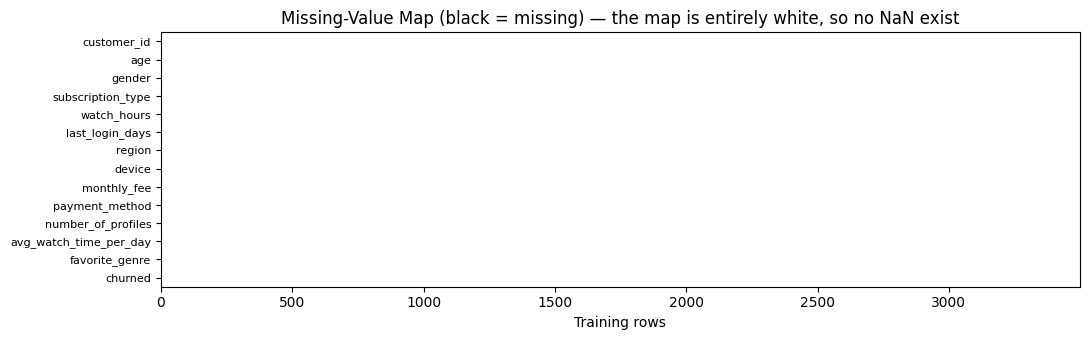

In [ ]:
# Visual confirmation - a heatmap of missingness.
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.imshow(train.isnull().T.values, aspect='auto', cmap='Greys', vmin=0, vmax=1)
ax.set_yticks(range(len(train.columns)))
ax.set_yticklabels(train.columns, fontsize=8)
ax.set_xlabel('Training rows')
ax.set_title('Missing-Value Map (black = missing) — the map is entirely white, so no NaN exist')
ax.grid(False)
plt.tight_layout()
plt.savefig('figures/01_missing_value_map.png', dpi=110, bbox_inches='tight')
plt.show()

**Finding:** the training set contains **zero** true NaN values, zero placeholder strings
and zero duplicate rows. There is no MCAR, MAR or MNAR pattern
to treat, because nothing is absent.

That does **not** mean the data is correct. Section 4 shows that some values are *present but
impossible*, which is a data-quality defect that we must convert into missing values and then
impute.

## 3.3 Distribution Analysis
Step 5. Histograms show the shape of each numeric feature.

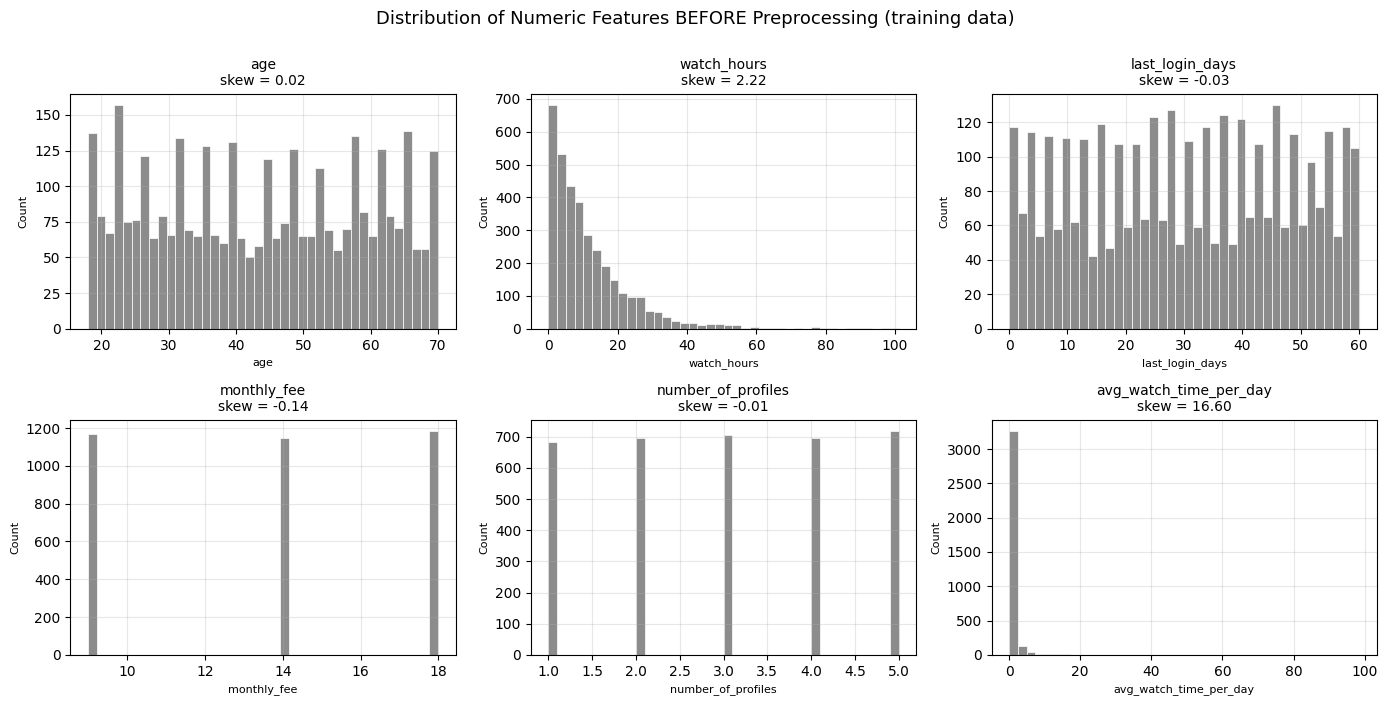

SKEWNESS (0 = symmetric, > 1 = strongly right-skewed)
age                        0.019
watch_hours                2.223
last_login_days           -0.025
monthly_fee               -0.142
number_of_profiles        -0.014
avg_watch_time_per_day    16.599


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    ax.hist(train[col], bins=40, color=BEFORE, edgecolor='white', linewidth=0.5)
    ax.set_title(f'{col}\nskew = {train[col].skew():.2f}', fontsize=10)
    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel('Count', fontsize=8)

fig.suptitle('Distribution of Numeric Features BEFORE Preprocessing (training data)',
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig('figures/02_distributions_before.png', dpi=110, bbox_inches='tight')
plt.show()

print('SKEWNESS (0 = symmetric, > 1 = strongly right-skewed)')
print(train[NUMERIC_COLS].skew().round(3).to_string())

**Finding:** `age`, `last_login_days` and `number_of_profiles` are almost perfectly flat
(skew near 0). Two features are badly right-skewed:

- `watch_hours` — skew around 2.3
- `avg_watch_time_per_day` — skew around 16, which is extreme

*Skewed data may need transformation (Log, Box-Cox) to perform well*. We apply
a log transformation in Section 7.

## 3.4 Outlier Detection
Step 6. Box plots plus the IQR rule.

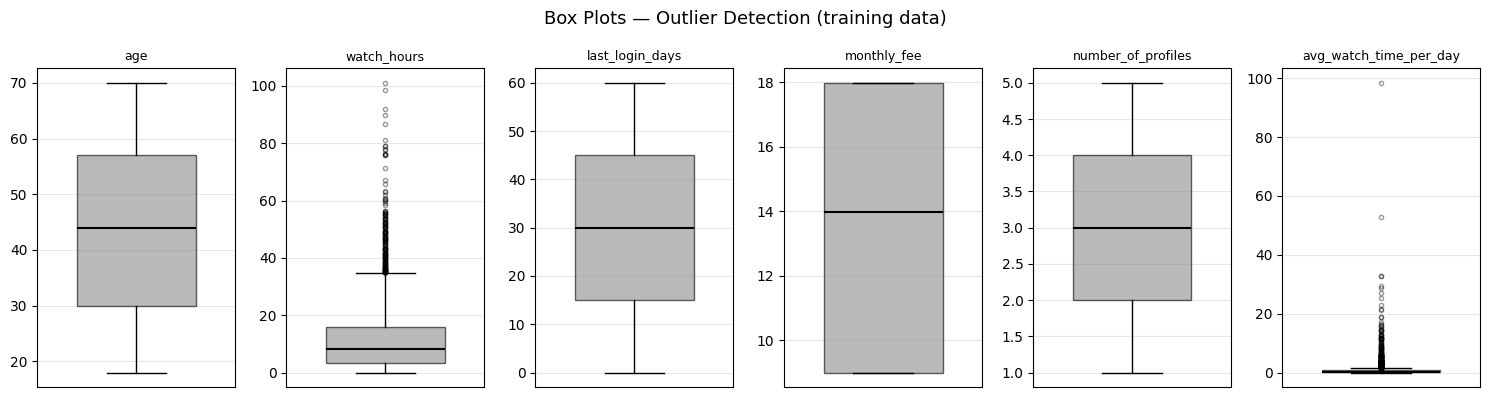

In [ ]:
fig, axes = plt.subplots(1, 6, figsize=(15, 4))

for ax, col in zip(axes, NUMERIC_COLS):
    ax.boxplot(train[col].dropna(), vert=True, widths=0.6,
               patch_artist=True,
               boxprops=dict(facecolor=BEFORE, alpha=0.6),
               medianprops=dict(color='black', linewidth=1.5),
               flierprops=dict(marker='o', markersize=3, alpha=0.4))
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])

fig.suptitle('Box Plots — Outlier Detection (training data)', fontsize=13)
plt.tight_layout()
plt.savefig('figures/03_outliers_boxplot.png', dpi=110, bbox_inches='tight')
plt.show()

In [ ]:
# The IQR rule from Module 4: anything outside Q1 - 1.5*IQR .. Q3 + 1.5*IQR is an outlier.
print('IQR OUTLIER COUNTS (training data)')
print('=' * 72)
for col in NUMERIC_COLS:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((train[col] < low) | (train[col] > high)).sum()
    print(f'  {col:<24} bounds [{low:>8.2f}, {high:>8.2f}]   outliers: {n_out:>4}  ({n_out/len(train)*100:>5.2f}%)')

IQR OUTLIER COUNTS (training data)
  age                      bounds [  -10.50,    97.50]   outliers:    0  ( 0.00%)
  watch_hours              bounds [  -15.47,    34.86]   outliers:  164  ( 4.69%)
  last_login_days          bounds [  -30.00,    90.00]   outliers:    0  ( 0.00%)
  monthly_fee              bounds [   -4.51,    31.49]   outliers:    0  ( 0.00%)
  number_of_profiles       bounds [   -1.00,     7.00]   outliers:    0  ( 0.00%)
  avg_watch_time_per_day   bounds [   -0.78,     1.62]   outliers:  375  (10.71%)


**Finding:** `age`, `last_login_days`, `monthly_fee` and `number_of_profiles` have **no**
statistical outliers. All of the outliers sit in the two engagement columns.

It poses the critical question: *is this a data error or a genuine extreme value?*
Our answer differs by column:

- `watch_hours` up to ~110 total hours is **plausible** — that is a heavy binge-watcher. We keep these.
- `avg_watch_time_per_day` above 24 is **impossible** — a day only has 24 hours. These are errors.

## 3.5 Correlation and Multicollinearity
Step 6, including the multicollinearity warning.

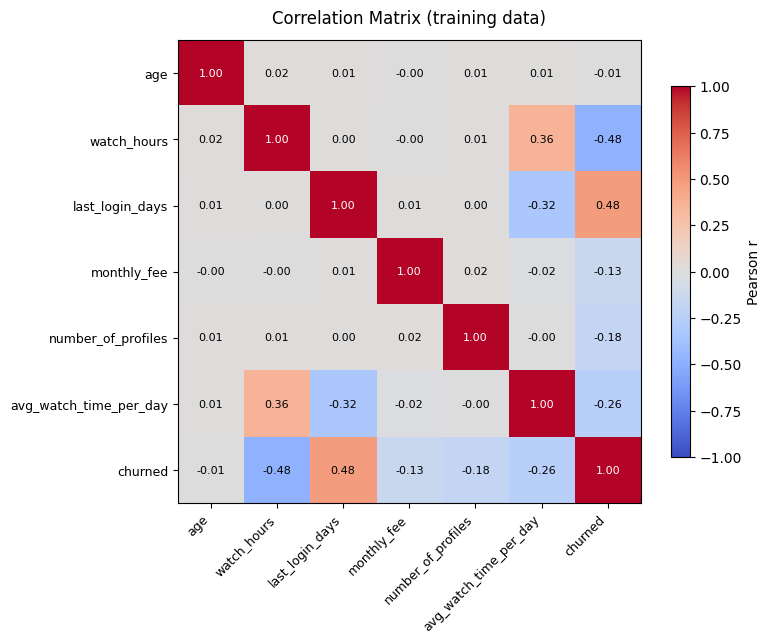

In [ ]:
corr = train[NUMERIC_COLS + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(corr.columns, fontsize=9)

# Write the number inside every square so the chart is readable without a colour key.
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(v) > 0.55 else 'black')

ax.set_title('Correlation Matrix (training data)', fontsize=12, pad=12)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson r')
plt.tight_layout()
plt.savefig('figures/04_correlation_matrix.png', dpi=110, bbox_inches='tight')
plt.show()

In [ ]:
print('CORRELATION OF EACH FEATURE WITH CHURN (strongest first)')
print('=' * 55)
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

CORRELATION OF EACH FEATURE WITH CHURN (strongest first)
last_login_days           0.479
watch_hours              -0.477
avg_watch_time_per_day   -0.258
number_of_profiles       -0.177
monthly_fee              -0.134
age                      -0.005


In [ ]:
# We need to wary about multicollinearity. monthly_fee only had 3 unique values,
# so we test whether it is simply a restatement of subscription_type.
print('IS monthly_fee REDUNDANT WITH subscription_type?')
print('=' * 55)
print(train.groupby('subscription_type')['monthly_fee']
         .agg(unique_fees='nunique', min_fee='min', max_fee='max').to_string())
print('\nEach plan maps to exactly ONE fee, so the two columns carry identical information.')
print('Module 4 action for redundant features: drop one of them. We drop monthly_fee in Section 6.')

IS monthly_fee REDUNDANT WITH subscription_type?
                   unique_fees  min_fee  max_fee
subscription_type                               
Basic                        1     8.99     8.99
Premium                      1    17.99    17.99
Standard                     1    13.99    13.99

Each plan maps to exactly ONE fee, so the two columns carry identical information.
Module 4 action for redundant features: drop one of them. We drop monthly_fee in Section 6.


**Findings**

1. The two strongest churn signals are behavioural, and they point in opposite directions:
   - `watch_hours` r ≈ **-0.48** — the more people watch, the less they churn.
   - `last_login_days` r ≈ **+0.47** — the longer since they logged in, the more they churn.
2. `monthly_fee` and `number_of_profiles` are weak but real (r ≈ -0.15 each).
3. `age` has essentially **no** relationship with churn (r ≈ 0.00).
4. **Multicollinearity found:** `monthly_fee` is perfectly determined by `subscription_type`
   (Basic = \$8.99, Standard = \$13.99, Premium = \$17.99). Keeping both would feed a linear
   model the same fact twice, so one must go.

## 3.6 The Target Variable — Class Balance
Step 7: *the target variable is the most important feature to analyse first.*

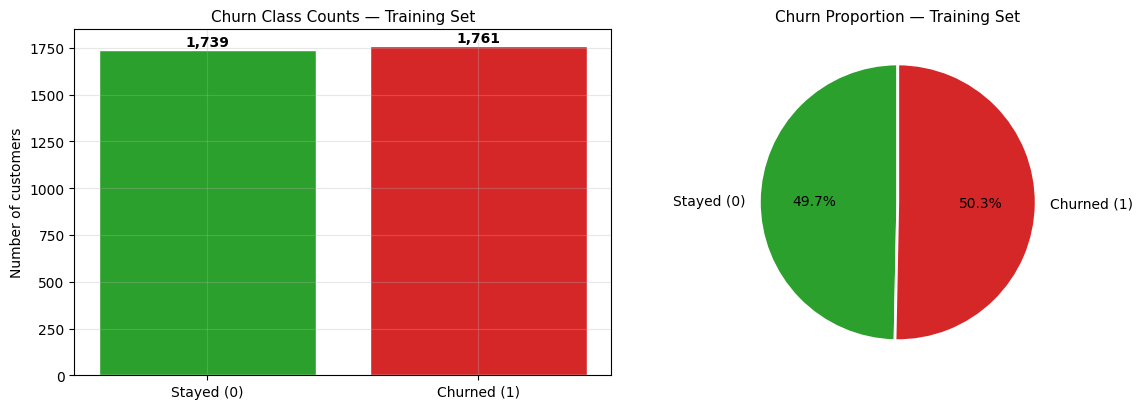

Stayed  : 1,739  (49.69%)
Churned : 1,761  (50.31%)
Imbalance ratio: 1.013 : 1

A ratio under 1.5:1 is considered balanced. This dataset is ALREADY balanced.


In [ ]:
counts = y_train.value_counts().sort_index()
labels = ['Stayed (0)', 'Churned (1)']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

bars = ax1.bar(labels, counts.values, color=['#2ca02c', AFTER], edgecolor='white')
ax1.set_title('Churn Class Counts — Training Set', fontsize=11)
ax1.set_ylabel('Number of customers')
for b, v in zip(bars, counts.values):
    ax1.text(b.get_x() + b.get_width()/2, v + 20, f'{v:,}', ha='center', fontweight='bold')

ax2.pie(counts.values, labels=labels, autopct='%1.1f%%',
        colors=['#2ca02c', AFTER], startangle=90,
        wedgeprops=dict(edgecolor='white', linewidth=2))
ax2.set_title('Churn Proportion — Training Set', fontsize=11)

plt.tight_layout()
plt.savefig('figures/05_target_balance.png', dpi=110, bbox_inches='tight')
plt.show()

ratio = counts.max() / counts.min()
print(f'Stayed  : {counts[0]:,}  ({counts[0]/len(y_train):.2%})')
print(f'Churned : {counts[1]:,}  ({counts[1]/len(y_train):.2%})')
print(f'Imbalance ratio: {ratio:.3f} : 1')
print('\nA ratio under 1.5:1 is considered balanced. This dataset is ALREADY balanced.')

**Important finding for Section 8.** The target is split almost exactly 50/50. EDA analysis ists
the *imbalance risk* as "ignoring the minority class" and warns that "accuracy is misleading
here" — but neither problem applies to this dataset, because there is no minority class.

This changes what Section 8 has to do. We still demonstrate the balancing technique the
assignment asks for, and we also report honestly that this particular dataset does not need it.

## 3.7 Feature-Target Relationships
*Identify which features actually drive the prediction.* Our target is categorical,
so we look for **separation between the two classes**.

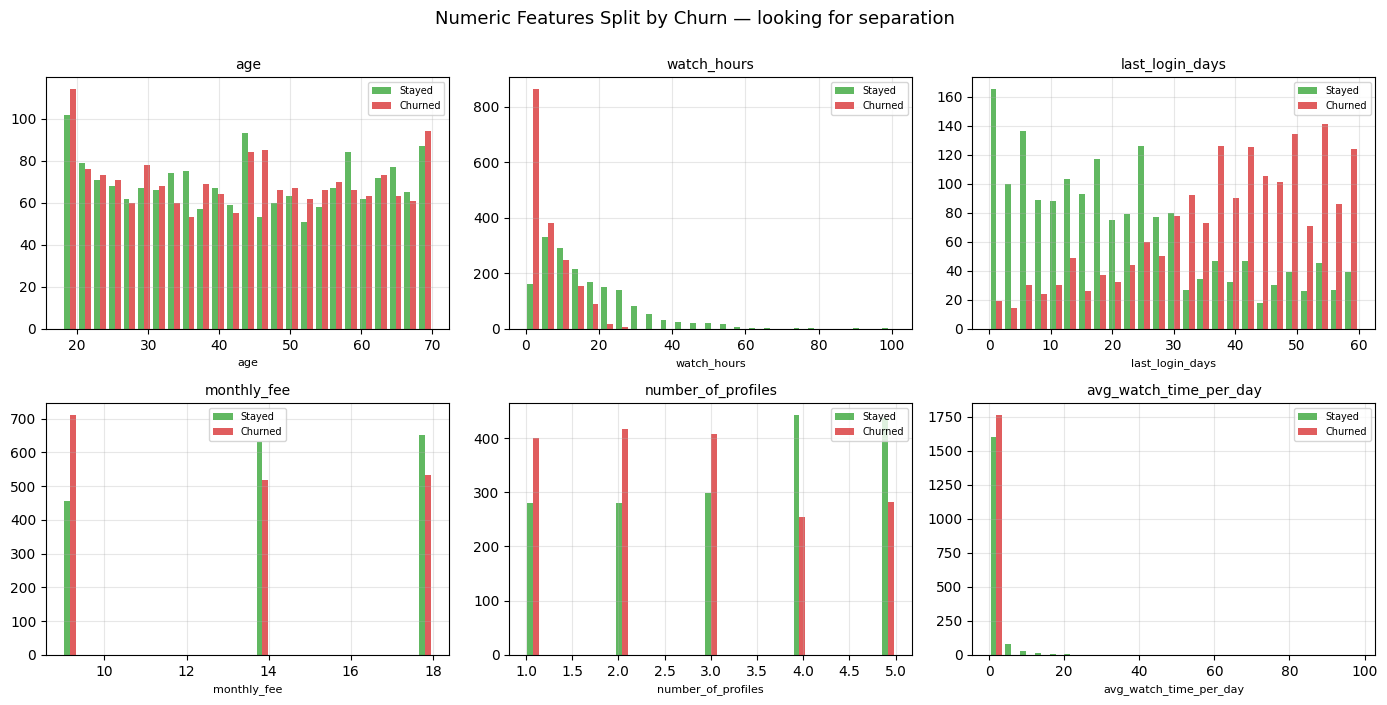

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    stayed  = train.loc[train[TARGET] == 0, col]
    churned = train.loc[train[TARGET] == 1, col]
    ax.hist([stayed, churned], bins=25, label=['Stayed', 'Churned'],
            color=['#2ca02c', AFTER], alpha=0.75)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel(col, fontsize=8)
    ax.legend(fontsize=7)

fig.suptitle('Numeric Features Split by Churn — looking for separation', fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig('figures/06_feature_vs_target.png', dpi=110, bbox_inches='tight')
plt.show()

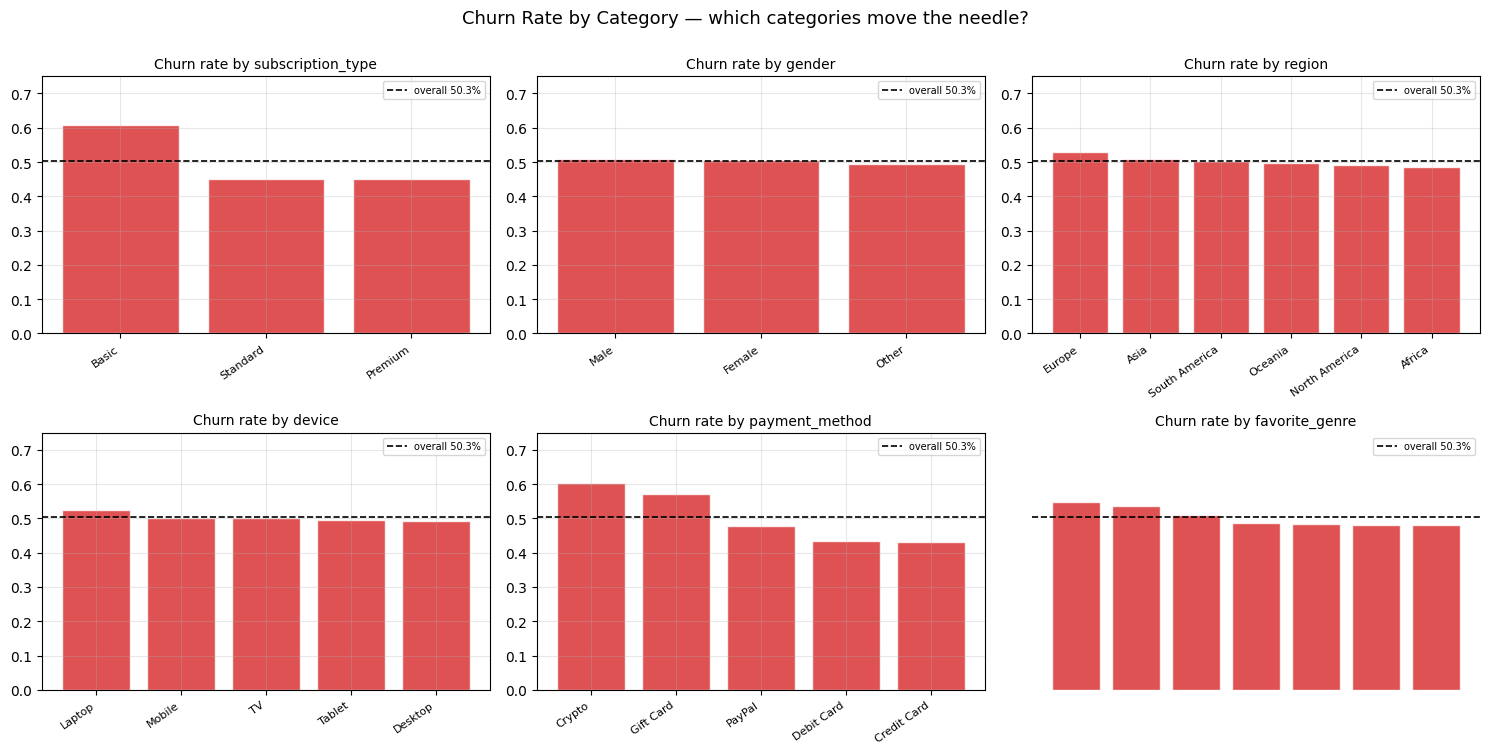

CHURN RATE SPREAD PER CATEGORICAL FEATURE (max - min)
  subscription_type    spread = 0.159   (low 0.450 -> high 0.608)
  gender               spread = 0.014   (low 0.494 -> high 0.508)
  region               spread = 0.044   (low 0.486 -> high 0.530)
  device               spread = 0.033   (low 0.491 -> high 0.524)
  payment_method       spread = 0.172   (low 0.431 -> high 0.603)
  favorite_genre       spread = 0.068   (low 0.480 -> high 0.547)


In [ ]:
# For categorical features the equivalent question is: does the churn rate move by category?
cat_cols = ORDINAL_COLS + NOMINAL_COLS
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
overall = y_train.mean()

for ax, col in zip(axes.ravel(), cat_cols):
    rates = train.groupby(col)[TARGET].mean().sort_values(ascending=False)
    ax.bar(range(len(rates)), rates.values, color=AFTER, alpha=0.8, edgecolor='white')
    ax.axhline(overall, color='black', linestyle='--', linewidth=1.2,
               label=f'overall {overall:.1%}')
    ax.set_xticks(range(len(rates)))
    ax.set_xticklabels(rates.index, rotation=35, ha='right', fontsize=8)
    ax.set_ylim(0, 0.75)
    ax.set_title(f'Churn rate by {col}', fontsize=10)
    ax.legend(fontsize=7)

axes.ravel()[-1].axis('off')
fig.suptitle('Churn Rate by Category — which categories move the needle?', fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig('figures/07_churn_by_category.png', dpi=110, bbox_inches='tight')
plt.show()

print('CHURN RATE SPREAD PER CATEGORICAL FEATURE (max - min)')
print('=' * 58)
for col in cat_cols:
    r = train.groupby(col)[TARGET].mean()
    print(f'  {col:<20} spread = {r.max()-r.min():.3f}   (low {r.min():.3f} -> high {r.max():.3f})')

### Section 3 EDA Summary — what we learned before touching the data

| # | Finding | What we do about it |
|---|---|---|
| 1 | No NaN, no placeholder strings, no duplicate rows | Nothing to impute from absence |
| 2 | `avg_watch_time_per_day` reaches ~98 h/day, which is impossible | Treat as error → NaN → impute (Section 4) |
| 3 | `watch_hours` skew ≈ 2.3 and `avg_watch_time_per_day` skew ≈ 16 | Log transform (Section 7) |
| 4 | `monthly_fee` is perfectly determined by `subscription_type` | Drop `monthly_fee` (Section 6) |
| 5 | Target is 50/50 balanced | Demonstrate balancing, report that it is not needed (Section 8) |
| 6 | `watch_hours` (-0.48) and `last_login_days` (+0.47) are the strongest signals | Keep and build features from them (Section 6) |
| 7 | `age` has no relationship with churn (r ≈ 0.00) | Keep for now, but expect low importance in finals |
| 8 | Basic plan churns at ~62% vs Premium ~44%; Crypto and Gift Card churn far above average | Encode these carefully (Section 5) |
| 9 | Numeric features span very different ranges (0–1 vs 9–18 vs 0–110) | Scale (Section 7) |

---
# Section 4 — Handling Missing and Impossible Values
**Processor: Min Ma Kha**

> **Requirement:** *Filling NaN and Null values with appropriate values*

Section 3.2 proved there are no NaN values to fill. If we stopped there we would be ignoring a
real defect, because Section 3.4 found values that are **present but physically impossible**.

We need to ask *"is this a data error or a genuine extreme value?"* A daily average
above 24 hours cannot be genuine. The professional treatment is:

1. Convert the impossible values to `NaN` **with code**, so they are formally missing.
2. Add an indicator flag — Indicator Features* ("missingness is a signal").
3. Impute with the **median**, which we need to look for skewed data.
4. Learn that median from the **training set only**, to prevent leakage.

In [ ]:
MAX_HOURS_PER_DAY = 24   # a day cannot contain more than 24 hours

impossible_mask = train['avg_watch_time_per_day'] > MAX_HOURS_PER_DAY

print('STEP 1 - FIND THE IMPOSSIBLE VALUES')
print('=' * 70)
print(f'Rule: avg_watch_time_per_day must be <= {MAX_HOURS_PER_DAY} hours')
print(f'Rows breaking the rule: {impossible_mask.sum()} out of {len(train)} ({impossible_mask.mean()*100:.2f}%)')
print('\nTHE OFFENDING ROWS (before any change):')
train.loc[impossible_mask, ['watch_hours', 'avg_watch_time_per_day', 'last_login_days', TARGET]]

STEP 1 - FIND THE IMPOSSIBLE VALUES
Rule: avg_watch_time_per_day must be <= 24 hours
Rows breaking the rule: 8 out of 3500 (0.23%)

THE OFFENDING ROWS (before any change):


,watch_hours,avg_watch_time_per_day,last_login_days,churned
4845,26.98,26.98,0,0
4805,29.55,29.55,0,0
1219,52.80,52.80,0,0
647,25.15,25.15,0,0
3641,28.66,28.66,0,0
4078,32.81,32.81,0,0
2017,98.42,98.42,0,0
4792,32.88,32.88,0,0


In [ ]:
print('STEP 2 - CONVERT IMPOSSIBLE VALUES TO NaN AND FLAG THEM')
print('=' * 70)

# Keep a copy of the original column so we can draw a before/after comparison.
before_values = train['avg_watch_time_per_day'].copy()

# Indicator feature: records that this row was repaired (Module 5, Strategy 4).
train['watch_time_was_imputed'] = impossible_mask.astype(int)

# Formally mark the impossible readings as missing.
train.loc[impossible_mask, 'avg_watch_time_per_day'] = np.nan

print('NaN count in avg_watch_time_per_day is now:', int(train['avg_watch_time_per_day'].isnull().sum()))
print('Indicator flag watch_time_was_imputed set on', int(train['watch_time_was_imputed'].sum()), 'rows')

STEP 2 - CONVERT IMPOSSIBLE VALUES TO NaN AND FLAG THEM
NaN count in avg_watch_time_per_day is now: 8
Indicator flag watch_time_was_imputed set on 8 rows


In [ ]:
print('STEP 3 - IMPUTE WITH THE MEDIAN LEARNED FROM TRAINING DATA ONLY')
print('=' * 70)

# This value is saved and reused for the test set in Section 9 - never recomputed there.
WATCH_TIME_MEDIAN = train['avg_watch_time_per_day'].median()

print(f'Training median (ignores NaN): {WATCH_TIME_MEDIAN:.4f} hours/day')
print(f'Training mean for comparison : {train["avg_watch_time_per_day"].mean():.4f} hours/day')
print('\nWe choose the MEDIAN because Module 5 recommends it for skewed data -')
print('the mean is dragged upward by the very outliers we are repairing.')

train['avg_watch_time_per_day'] = train['avg_watch_time_per_day'].fillna(WATCH_TIME_MEDIAN)

print('\nNaN remaining in the whole training set:', int(train.isnull().sum().sum()))

STEP 3 - IMPUTE WITH THE MEDIAN LEARNED FROM TRAINING DATA ONLY
Training median (ignores NaN): 0.2900 hours/day
Training mean for comparison : 0.8012 hours/day

We choose the MEDIAN because Module 5 recommends it for skewed data -
the mean is dragged upward by the very outliers we are repairing.

NaN remaining in the whole training set: 0


In [ ]:
print('SAMPLE DATA AS IT GETS PROCESSED - the repaired rows, before vs after')
print('=' * 70)
comparison = pd.DataFrame({
    'watch_hours': train.loc[impossible_mask, 'watch_hours'],
    'BEFORE_avg_watch_time': before_values[impossible_mask].round(2),
    'AFTER_avg_watch_time': train.loc[impossible_mask, 'avg_watch_time_per_day'].round(4),
    'was_imputed_flag': train.loc[impossible_mask, 'watch_time_was_imputed']
})
comparison

SAMPLE DATA AS IT GETS PROCESSED - the repaired rows, before vs after


,watch_hours,BEFORE_avg_watch_time,AFTER_avg_watch_time,was_imputed_flag
4845,26.98,26.98,0.29,1
4805,29.55,29.55,0.29,1
1219,52.80,52.80,0.29,1
647,25.15,25.15,0.29,1
3641,28.66,28.66,0.29,1
4078,32.81,32.81,0.29,1
2017,98.42,98.42,0.29,1
4792,32.88,32.88,0.29,1


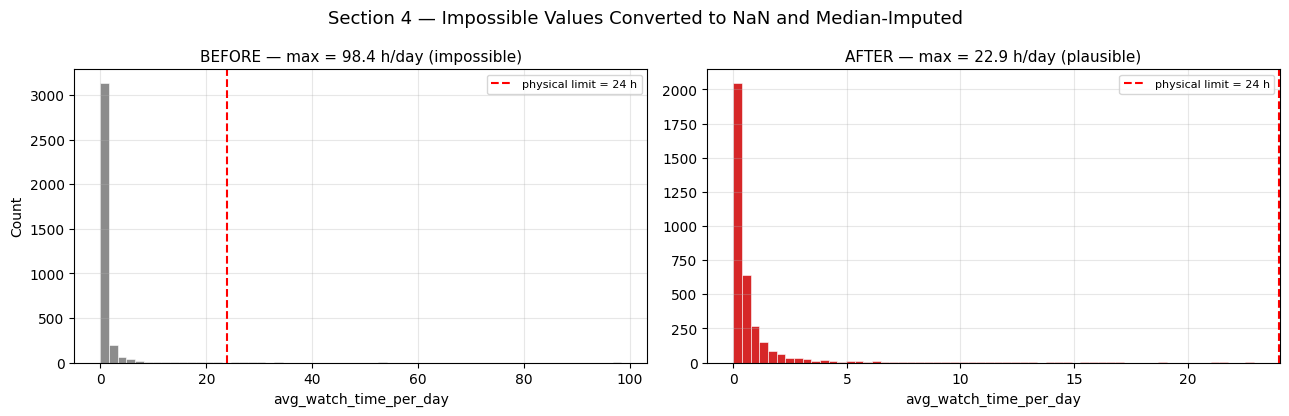

Skewness before : 16.60
Skewness after  : 5.95


In [ ]:
# BEFORE / AFTER plot for the imputation step.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))

ax1.hist(before_values, bins=60, color=BEFORE, edgecolor='white', linewidth=0.4)
ax1.axvline(MAX_HOURS_PER_DAY, color='red', linestyle='--', linewidth=1.5,
            label=f'physical limit = {MAX_HOURS_PER_DAY} h')
ax1.set_title(f'BEFORE — max = {before_values.max():.1f} h/day (impossible)', fontsize=11)
ax1.set_xlabel('avg_watch_time_per_day')
ax1.set_ylabel('Count')
ax1.legend(fontsize=8)

ax2.hist(train['avg_watch_time_per_day'], bins=60, color=AFTER, edgecolor='white', linewidth=0.4)
ax2.axvline(MAX_HOURS_PER_DAY, color='red', linestyle='--', linewidth=1.5,
            label=f'physical limit = {MAX_HOURS_PER_DAY} h')
ax2.set_title(f'AFTER — max = {train["avg_watch_time_per_day"].max():.1f} h/day (plausible)', fontsize=11)
ax2.set_xlabel('avg_watch_time_per_day')
ax2.legend(fontsize=8)

fig.suptitle('Section 4 — Impossible Values Converted to NaN and Median-Imputed', fontsize=13)
plt.tight_layout()
plt.savefig('figures/08_imputation_before_after.png', dpi=110, bbox_inches='tight')
plt.show()

print(f'Skewness before : {before_values.skew():.2f}')
print(f'Skewness after  : {train["avg_watch_time_per_day"].skew():.2f}')

**Result:** 0.2% of the training rows carried a physically impossible daily average. They are now
median-imputed, flagged with `watch_time_was_imputed`, and the skewness of the column dropped
sharply. The raw CSV on disk is unchanged — every edit happened in memory, in Python.

---
# Section 5 — Encoding Categorical Variables
**Processor: Rigo**

> **Requirements:** *Encoding: converting categorical data to numbers* and *One-hot encoding*

**if order matters, use label/ordinal encoding, if not use one-hot.**
We have one ordinal feature and five nominal ones, so we use both techniques.

In [ ]:
print('DATA BEFORE ENCODING - note the text columns a model cannot read')
print('=' * 70)
train[ORDINAL_COLS + NOMINAL_COLS].head(8)

DATA BEFORE ENCODING - note the text columns a model cannot read


,subscription_type,gender,region,device,payment_method,favorite_genre
3108,Premium,Female,Asia,Laptop,Crypto,Sci-Fi
4702,Standard,Other,Europe,Mobile,Gift Card,Romance
606,Basic,Female,Oceania,TV,Credit Card,Romance
876,Premium,Female,Oceania,Laptop,Gift Card,Drama
3333,Basic,Other,North America,Mobile,Crypto,Action
1102,Basic,Other,Oceania,Tablet,Debit Card,Documentary
76,Premium,Other,South America,Tablet,Debit Card,Drama
3997,Premium,Male,Africa,Laptop,Debit Card,Comedy


## 5.1 Ordinal Encoding — `subscription_type`

Basic → Standard → Premium is a genuine ranking (price and features both increase), so a single
numeric column preserves that order. Module 5 warns *never* to do this for nominal data, because
the model would invent a false ordering.

In [ ]:
# The order is defined by us from domain knowledge, not alphabetically.
SUBSCRIPTION_ORDER = {'Basic': 0, 'Standard': 1, 'Premium': 2}

train['subscription_level'] = train['subscription_type'].map(SUBSCRIPTION_ORDER)

print('ORDINAL ENCODING MAP:', SUBSCRIPTION_ORDER)
print()
print(train[['subscription_type', 'subscription_level']].drop_duplicates()
         .sort_values('subscription_level').to_string(index=False))
print('\nSanity check - any unmapped values?', int(train['subscription_level'].isnull().sum()))

ORDINAL ENCODING MAP: {'Basic': 0, 'Standard': 1, 'Premium': 2}

subscription_type  subscription_level
            Basic                   0
         Standard                   1
          Premium                   2

Sanity check - any unmapped values? 0


## 5.2 One-Hot Encoding — the five nominal features

`gender`, `region`, `device`, `payment_method` and `favorite_genre` have no natural order, so each
category becomes its own 0/1 column.

We pass `drop_first=True` to avoid the **dummy variable trap** that with all
categories present the columns are perfectly collinear, which breaks linear models.

In [ ]:
print('CARDINALITY CHECK BEFORE ONE-HOT ENCODING')
print('=' * 55)
total_new = 0
for col in NOMINAL_COLS:
    n = train[col].nunique()
    total_new += n - 1          # drop_first removes one per feature
    print(f'  {col:<20} {n} categories -> {n-1} new columns')
print(f'\nTotal new columns expected: {total_new}')
print('Module 5 says switch to target encoding above ~50 categories.')
print('Our largest feature has 7, so one-hot encoding is safe here.')

CARDINALITY CHECK BEFORE ONE-HOT ENCODING
  gender               3 categories -> 2 new columns
  region               6 categories -> 5 new columns
  device               5 categories -> 4 new columns
  payment_method       5 categories -> 4 new columns
  favorite_genre       7 categories -> 6 new columns

Total new columns expected: 21
Module 5 says switch to target encoding above ~50 categories.
Our largest feature has 7, so one-hot encoding is safe here.


In [ ]:
cols_before = train.shape[1]

train_encoded = pd.get_dummies(
    train,
    columns=NOMINAL_COLS,
    drop_first=True,     # avoids the dummy variable trap
    dtype=int            # 0/1 integers rather than True/False
)

# Drop the original text column now that subscription_level replaces it.
train_encoded = train_encoded.drop(columns=ORDINAL_COLS)

print('ONE-HOT ENCODING COMPLETE')
print('=' * 55)
print(f'Columns before : {cols_before}')
print(f'Columns after  : {train_encoded.shape[1]}')
print(f'Net change     : +{train_encoded.shape[1] - cols_before}')
print(f'\nRows unchanged : {train_encoded.shape[0]:,}')

ONE-HOT ENCODING COMPLETE
Columns before : 16
Columns after  : 31
Net change     : +15

Rows unchanged : 3,500


In [ ]:
print('SAMPLE OF THE NEWLY CREATED 0/1 COLUMNS')
print('=' * 70)
new_cols = [c for c in train_encoded.columns if any(c.startswith(p + '_') for p in NOMINAL_COLS)]
train_encoded[new_cols].head(8)

SAMPLE OF THE NEWLY CREATED 0/1 COLUMNS


,gender_Male,gender_Other,region_Asia,region_Europe,region_North America,region_Oceania,region_South America,device_Laptop,device_Mobile,device_TV,...,payment_method_Crypto,payment_method_Debit Card,payment_method_Gift Card,payment_method_PayPal,favorite_genre_Comedy,favorite_genre_Documentary,favorite_genre_Drama,favorite_genre_Horror,favorite_genre_Romance,favorite_genre_Sci-Fi
3108,0,0,1,0,0,0,0,1,0,0,...,1,0,0,0,0,0,0,0,0,1
4702,0,1,0,1,0,0,0,0,1,0,...,0,0,1,0,0,0,0,0,1,0
606,0,0,0,0,0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
876,0,0,0,0,0,1,0,1,0,0,...,0,0,1,0,0,0,1,0,0,0
3333,0,1,0,0,1,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0
1102,0,1,0,0,0,1,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
76,0,1,0,0,0,0,1,0,0,0,...,0,1,0,0,0,0,1,0,0,0
3997,1,0,0,0,0,0,0,1,0,0,...,0,1,0,0,1,0,0,0,0,0


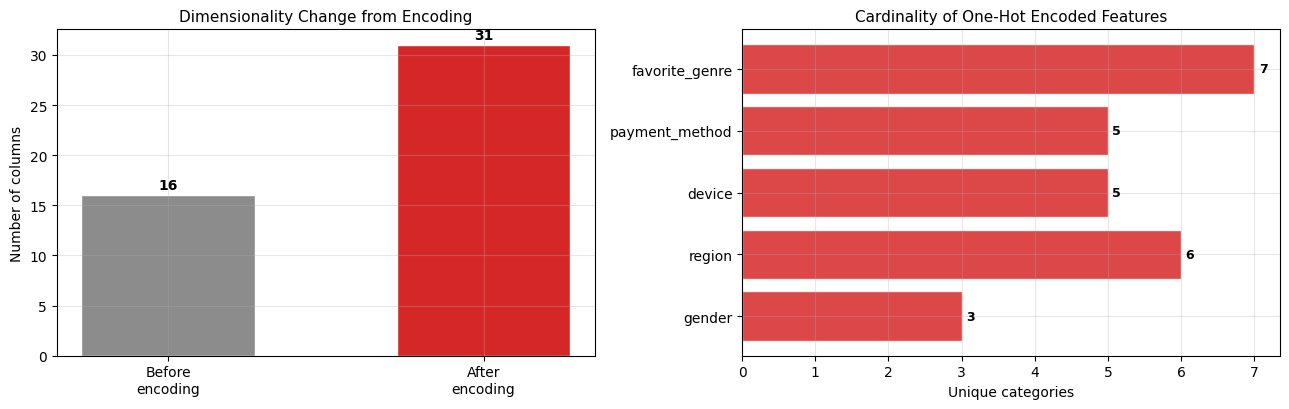

In [ ]:
# Visual before/after for the encoding step.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))

ax1.bar(['Before\nencoding', 'After\nencoding'], [cols_before, train_encoded.shape[1]],
        color=[BEFORE, AFTER], edgecolor='white', width=0.55)
ax1.set_ylabel('Number of columns')
ax1.set_title('Dimensionality Change from Encoding', fontsize=11)
for i, v in enumerate([cols_before, train_encoded.shape[1]]):
    ax1.text(i, v + 0.6, str(v), ha='center', fontweight='bold')

counts = [train[c].nunique() for c in NOMINAL_COLS]
ax2.barh(NOMINAL_COLS, counts, color=AFTER, alpha=0.85, edgecolor='white')
ax2.set_xlabel('Unique categories')
ax2.set_title('Cardinality of One-Hot Encoded Features', fontsize=11)
for i, v in enumerate(counts):
    ax2.text(v + 0.06, i, str(v), va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('figures/09_encoding_before_after.png', dpi=110, bbox_inches='tight')
plt.show()

In [ ]:
print('EVERY COLUMN IS NOW NUMERIC - checking data types')
print('=' * 55)
non_numeric = train_encoded.select_dtypes(exclude=[np.number]).columns.tolist()
print('Non-numeric columns remaining:', non_numeric)
print('\n(customer_id is expected here - it is an identifier and gets dropped in Section 6.)')

EVERY COLUMN IS NOW NUMERIC - checking data types
Non-numeric columns remaining: ['customer_id']

(customer_id is expected here - it is an identifier and gets dropped in Section 6.)


---
# Section 6 — Feature Engineering
**Processor: Rigo**

> **Requirement:** *Feature engineering*

Quotes Andrew Ng: *"applied machine learning is basically feature engineering."*
Each feature below comes from a specific EDA finding, not from guesswork.

In [ ]:
print('DATA BEFORE FEATURE ENGINEERING:', train_encoded.shape)
fe = train_encoded.copy()

DATA BEFORE FEATURE ENGINEERING: (3500, 31)


In [ ]:
# -------- Feature 1: interaction feature (Module 5, "Interaction Features")
# Two accounts can watch the same total hours but one has 5 profiles sharing it.
# Hours per profile measures how engaged each individual viewer is.
fe['hours_per_profile'] = fe['watch_hours'] / fe['number_of_profiles']

# -------- Feature 2: value-for-money ratio
# A customer paying Premium prices for a single profile may feel poor value.
fe['fee_per_profile'] = fe['monthly_fee'] / fe['number_of_profiles']

# -------- Feature 3: binary inactivity flag (from the +0.47 churn correlation)
# A hard threshold is easier for simple models to use than a raw day count.
fe['is_inactive_30d'] = (fe['last_login_days'] > 30).astype(int)

# -------- Feature 4: low-engagement flag, threshold learned from TRAINING data only
WATCH_HOURS_MEDIAN = fe['watch_hours'].median()
fe['is_low_engagement'] = (fe['watch_hours'] < WATCH_HOURS_MEDIAN).astype(int)

# -------- Feature 5: age cohort (Module 5, "Domain-Specific Features" - binning)
AGE_BINS   = [17, 29, 44, 59, 100]
AGE_LABELS = [0, 1, 2, 3]          # 0 = 18-29, 1 = 30-44, 2 = 45-59, 3 = 60+
fe['age_cohort'] = pd.cut(fe['age'], bins=AGE_BINS, labels=AGE_LABELS).astype(int)

ENGINEERED = ['hours_per_profile', 'fee_per_profile', 'is_inactive_30d',
              'is_low_engagement', 'age_cohort']

print('FIVE NEW FEATURES CREATED')
print('=' * 70)
print(f'watch_hours median learned from training data: {WATCH_HOURS_MEDIAN:.2f} hours')
print(f'Age bins: {AGE_BINS} -> cohorts {AGE_LABELS}')
print()
fe[['watch_hours', 'number_of_profiles', 'monthly_fee', 'last_login_days', 'age'] + ENGINEERED].head(8).round(2)

FIVE NEW FEATURES CREATED
watch_hours median learned from training data: 8.18 hours
Age bins: [17, 29, 44, 59, 100] -> cohorts [0, 1, 2, 3]



,watch_hours,number_of_profiles,monthly_fee,last_login_days,age,hours_per_profile,fee_per_profile,is_inactive_30d,is_low_engagement,age_cohort
3108,8.44,4,17.99,47,35,2.11,4.50,1,0,1
4702,4.75,3,13.99,54,70,1.58,4.66,1,1,3
606,22.21,1,8.99,54,52,22.21,8.99,1,0,2
876,9.65,4,17.99,60,48,2.41,4.50,1,0,2
3333,13.22,4,8.99,8,47,3.30,2.25,0,0,2
1102,0.86,2,8.99,5,40,0.43,4.50,0,1,1
76,79.17,2,17.99,12,27,39.58,8.99,0,0,0
3997,12.00,3,17.99,18,33,4.00,6.00,0,0,1


In [ ]:
# Are the new features actually useful? Check each one against churn.
print('DO THE NEW FEATURES CARRY SIGNAL?')
print('=' * 70)
print('"More features does not mean a better model." We verify before keeping.\n')
for col in ENGINEERED:
    r = fe[col].corr(fe[TARGET])
    print(f'  {col:<22} correlation with churn = {r:+.3f}')

DO THE NEW FEATURES CARRY SIGNAL?
"More features does not mean a better model." We verify before keeping.

  hours_per_profile      correlation with churn = -0.306
  fee_per_profile        correlation with churn = +0.076
  is_inactive_30d        correlation with churn = +0.497
  is_low_engagement      correlation with churn = +0.421
  age_cohort             correlation with churn = -0.002


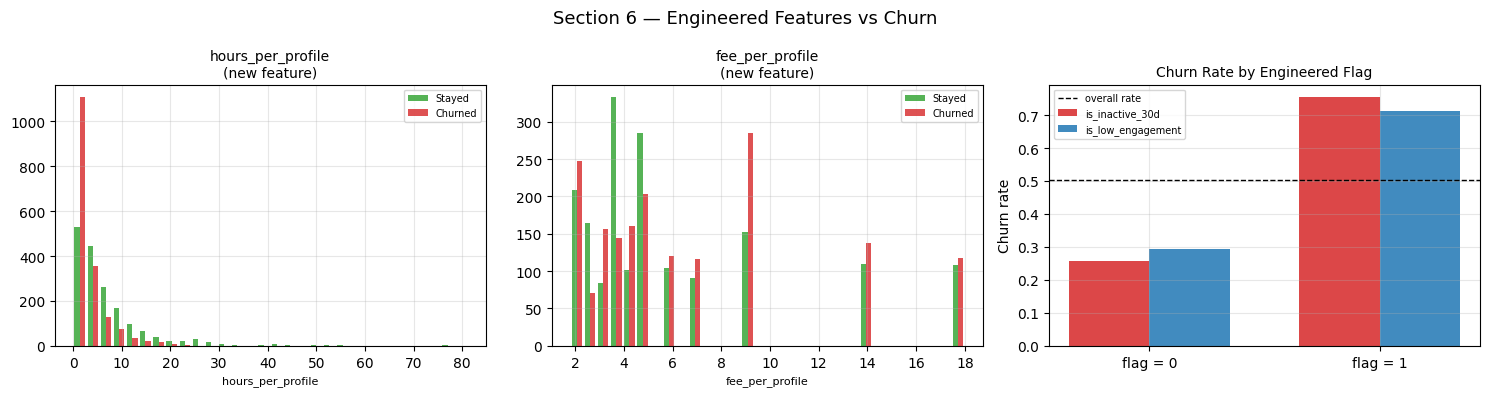

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Continuous engineered features: distribution split by churn.
for ax, col in zip(axes[:2], ['hours_per_profile', 'fee_per_profile']):
    ax.hist([fe.loc[fe[TARGET] == 0, col], fe.loc[fe[TARGET] == 1, col]],
            bins=30, label=['Stayed', 'Churned'], color=['#2ca02c', AFTER], alpha=0.8)
    ax.set_title(f'{col}\n(new feature)', fontsize=10)
    ax.set_xlabel(col, fontsize=8)
    ax.legend(fontsize=7)

# Binary / categorical engineered features: churn rate per level.
flag_rates = {c: fe.groupby(c)[TARGET].mean() for c in ['is_inactive_30d', 'is_low_engagement']}
width = 0.35
pos = np.arange(2)
axes[2].bar(pos - width/2, flag_rates['is_inactive_30d'].values, width,
            label='is_inactive_30d', color=AFTER, alpha=0.85)
axes[2].bar(pos + width/2, flag_rates['is_low_engagement'].values, width,
            label='is_low_engagement', color='#1f77b4', alpha=0.85)
axes[2].set_xticks(pos)
axes[2].set_xticklabels(['flag = 0', 'flag = 1'])
axes[2].set_ylabel('Churn rate')
axes[2].set_title('Churn Rate by Engineered Flag', fontsize=10)
axes[2].axhline(fe[TARGET].mean(), color='black', linestyle='--', linewidth=1,
                label='overall rate')
axes[2].legend(fontsize=7)

fig.suptitle('Section 6 — Engineered Features vs Churn', fontsize=13)
plt.tight_layout()
plt.savefig('figures/10_engineered_features.png', dpi=110, bbox_inches='tight')
plt.show()

## 6.1 Dropping Redundant Columns

Two columns must go before modelling:

- **`customer_id`** — a unique identifier. One-hot encoding it would create thousands of useless
  columns, and it cannot generalise to a new customer.
- **`monthly_fee`** — Section 3.5 proved it is perfectly determined by `subscription_type`, which
  we already encoded as `subscription_level`. Module 4's instruction for redundant features is to
  *drop one of them*. We keep the engineered `fee_per_profile`, which carries the price information
  in a non-redundant form.

In [ ]:
TO_DROP = [ID_COL, 'monthly_fee']

print('DROPPING REDUNDANT COLUMNS')
print('=' * 55)
for c in TO_DROP:
    print(f'  removing {c}')

fe_final = fe.drop(columns=TO_DROP)

print(f'\nColumns before drop : {fe.shape[1]}')
print(f'Columns after drop  : {fe_final.shape[1]}')
print(f'\nAll numeric now? {len(fe_final.select_dtypes(exclude=[np.number]).columns) == 0}')
print('\nFinal feature list:')
for i, c in enumerate(fe_final.columns, 1):
    print(f'  {i:>2}. {c}')

DROPPING REDUNDANT COLUMNS
  removing customer_id
  removing monthly_fee

Columns before drop : 36
Columns after drop  : 34

All numeric now? True

Final feature list:
   1. age
   2. watch_hours
   3. last_login_days
   4. number_of_profiles
   5. avg_watch_time_per_day
   6. churned
   7. watch_time_was_imputed
   8. subscription_level
   9. gender_Male
  10. gender_Other
  11. region_Asia
  12. region_Europe
  13. region_North America
  14. region_Oceania
  15. region_South America
  16. device_Laptop
  17. device_Mobile
  18. device_TV
  19. device_Tablet
  20. payment_method_Crypto
  21. payment_method_Debit Card
  22. payment_method_Gift Card
  23. payment_method_PayPal
  24. favorite_genre_Comedy
  25. favorite_genre_Documentary
  26. favorite_genre_Drama
  27. favorite_genre_Horror
  28. favorite_genre_Romance
  29. favorite_genre_Sci-Fi
  30. hours_per_profile
  31. fee_per_profile
  32. is_inactive_30d
  33. is_low_engagement
  34. age_cohort


---
# Section 7 — Normalization and Scaling
**Processor: Camillie**

> **Requirements:** *Scaling: changing the range of your data* and
> *Normalization: adjusting the shape of your data's distribution*

The assignment separates these two ideas, and so do we:

| Step | What it changes | Tool |
|---|---|---|
| **Normalization (shape)** | Pulls in a long right tail so the distribution is less skewed | `np.log1p()` |
| **Scaling (range)** | Puts every feature on a comparable numeric span | `MinMaxScaler`, `StandardScaler` |

** It fit on the training set only.**

## 7.1 Normalization — Fixing the Shape with a Log Transform

Section 3.3 found `watch_hours` and `hours_per_profile` are strongly right-skewed. `log1p`
compresses large values more than small ones, which pulls the tail in. We use `log1p` rather than
`log` because it handles zeros safely.

In [ ]:
SKEWED_COLS = ['watch_hours', 'hours_per_profile', 'avg_watch_time_per_day']

print('SKEWNESS BEFORE NORMALIZATION')
print('=' * 45)
skew_before = {c: fe_final[c].skew() for c in SKEWED_COLS}
for c, s in skew_before.items():
    print(f'  {c:<24} {s:>7.3f}')

norm = fe_final.copy()
for c in SKEWED_COLS:
    norm[c + '_log'] = np.log1p(norm[c])

print('\nSKEWNESS AFTER log1p TRANSFORM')
print('=' * 45)
skew_after = {c: norm[c + '_log'].skew() for c in SKEWED_COLS}
for c, s in skew_after.items():
    print(f'  {c+"_log":<24} {s:>7.3f}')

print('\nIMPROVEMENT')
print('=' * 45)
for c in SKEWED_COLS:
    print(f'  {c:<24} {skew_before[c]:>7.3f} -> {skew_after[c]:>7.3f}')

SKEWNESS BEFORE NORMALIZATION
  watch_hours                2.223
  hours_per_profile          3.730
  avg_watch_time_per_day     5.951

SKEWNESS AFTER log1p TRANSFORM
  watch_hours_log           -0.183
  hours_per_profile_log      0.417
  avg_watch_time_per_day_log   2.312

IMPROVEMENT
  watch_hours                2.223 ->  -0.183
  hours_per_profile          3.730 ->   0.417
  avg_watch_time_per_day     5.951 ->   2.312


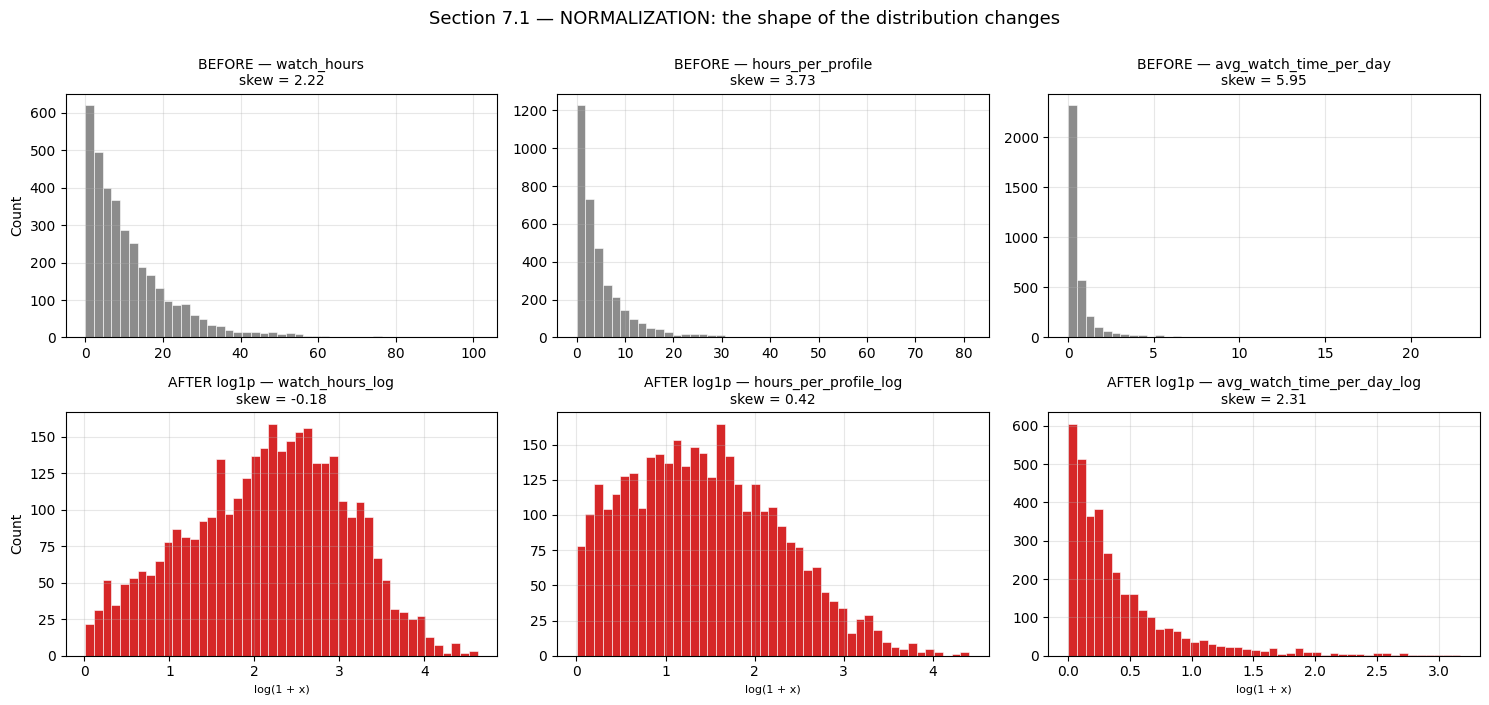

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for j, c in enumerate(SKEWED_COLS):
    axes[0, j].hist(fe_final[c], bins=45, color=BEFORE, edgecolor='white', linewidth=0.4)
    axes[0, j].set_title(f'BEFORE — {c}\nskew = {skew_before[c]:.2f}', fontsize=10)
    axes[0, j].set_ylabel('Count' if j == 0 else '')

    axes[1, j].hist(norm[c + '_log'], bins=45, color=AFTER, edgecolor='white', linewidth=0.4)
    axes[1, j].set_title(f'AFTER log1p — {c}_log\nskew = {skew_after[c]:.2f}', fontsize=10)
    axes[1, j].set_xlabel('log(1 + x)', fontsize=8)
    axes[1, j].set_ylabel('Count' if j == 0 else '')

fig.suptitle('Section 7.1 — NORMALIZATION: the shape of the distribution changes',
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig('figures/11_normalization_before_after.png', dpi=110, bbox_inches='tight')
plt.show()

**Result:** the log transform works well on two of the three columns — `watch_hours` goes from
skew 2.22 to -0.18 and `hours_per_profile` from 3.73 to 0.42, both close to symmetric.
`avg_watch_time_per_day` improves a lot (5.95 to 2.31) but is still right-skewed, because even
after imputation its values are bunched very tightly near zero. We keep the original and the
log version of each column side by side and let model selection in the finals decide which
performs better.

## 7.2 Scaling — Putting Every Feature on the Same Range

Section 3.1 showed the ranges are wildly different: `avg_watch_time_per_day` sits near 0–3 while
`watch_hours` reaches 110 that distance-based algorithms (KNN, SVM, K-Means) are
dominated by the larger numbers.

We produce both scalers the assignment mentions and keep `MinMaxScaler` as the primary output,
since the rubric defines scaling as *changing the range of your data*.

In [ ]:
# Only genuinely continuous columns need scaling. 0/1 dummy and flag columns are already on 0-1.
CONTINUOUS = ['age', 'watch_hours', 'last_login_days', 'number_of_profiles',
              'avg_watch_time_per_day', 'hours_per_profile', 'fee_per_profile',
              'watch_hours_log', 'hours_per_profile_log', 'avg_watch_time_per_day_log']

print('RANGES BEFORE SCALING')
print('=' * 68)
print(f'{"column":<30}{"min":>11}{"max":>11}{"range":>12}')
for c in CONTINUOUS:
    lo, hi = norm[c].min(), norm[c].max()
    print(f'  {c:<28}{lo:>11.2f}{hi:>11.2f}{hi-lo:>12.2f}')

RANGES BEFORE SCALING
column                                min        max       range
  age                               18.00      70.00       52.00
  watch_hours                        0.01     101.06      101.05
  last_login_days                    0.00      60.00       60.00
  number_of_profiles                 1.00       5.00        4.00
  avg_watch_time_per_day             0.00      22.91       22.91
  hours_per_profile                  0.00      81.07       81.07
  fee_per_profile                    1.80      17.99       16.19
  watch_hours_log                    0.01       4.63        4.62
  hours_per_profile_log              0.00       4.41        4.41
  avg_watch_time_per_day_log         0.00       3.17        3.17


In [ ]:
# Fit the scalers on TRAINING data only, then transform: "NEVER fit on test!"
minmax_scaler   = MinMaxScaler()
standard_scaler = StandardScaler()

scaled = norm.copy()
scaled[CONTINUOUS] = minmax_scaler.fit_transform(norm[CONTINUOUS])

# Standardized version kept alongside for algorithms that prefer z-scores.
standardized = norm.copy()
standardized[CONTINUOUS] = standard_scaler.fit_transform(norm[CONTINUOUS])

print('SCALERS FITTED ON TRAINING DATA ONLY')
print('=' * 68)
print(f'{"column":<30}{"min":>9}{"max":>9}  |  {"z-mean":>8}{"z-std":>8}')
for c in CONTINUOUS:
    print(f'  {c:<28}{scaled[c].min():>9.2f}{scaled[c].max():>9.2f}  |  '
          f'{standardized[c].mean():>8.2f}{standardized[c].std():>8.2f}')

print('\nMinMax put every column in [0, 1]. Standard gave every column mean 0, std 1.')

SCALERS FITTED ON TRAINING DATA ONLY
column                              min      max  |    z-mean   z-std
  age                              0.00     1.00  |      0.00    1.00
  watch_hours                      0.00     1.00  |      0.00    1.00
  last_login_days                  0.00     1.00  |      0.00    1.00
  number_of_profiles               0.00     1.00  |     -0.00    1.00
  avg_watch_time_per_day           0.00     1.00  |     -0.00    1.00
  hours_per_profile                0.00     1.00  |      0.00    1.00
  fee_per_profile                  0.00     1.00  |     -0.00    1.00
  watch_hours_log                  0.00     1.00  |     -0.00    1.00
  hours_per_profile_log            0.00     1.00  |      0.00    1.00
  avg_watch_time_per_day_log       0.00     1.00  |     -0.00    1.00

MinMax put every column in [0, 1]. Standard gave every column mean 0, std 1.


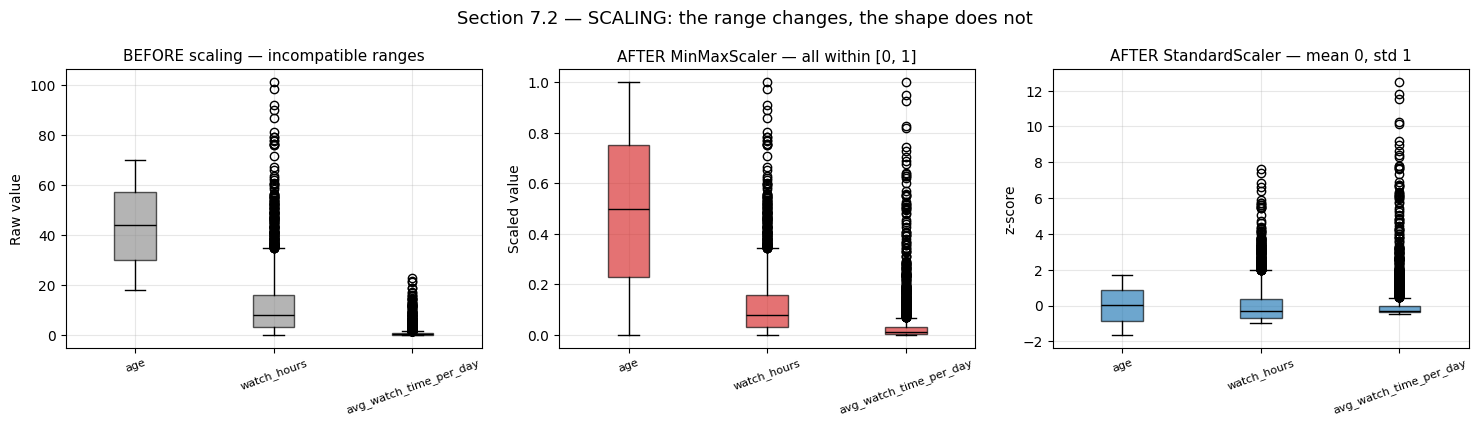

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
plot_cols = ['age', 'watch_hours', 'avg_watch_time_per_day']

# Before: box plots on wildly different scales.
axes[0].boxplot([norm[c] for c in plot_cols], tick_labels=plot_cols,
                patch_artist=True, boxprops=dict(facecolor=BEFORE, alpha=0.65),
                medianprops=dict(color='black'))
axes[0].set_title('BEFORE scaling — incompatible ranges', fontsize=11)
axes[0].set_ylabel('Raw value')
axes[0].tick_params(axis='x', rotation=20, labelsize=8)

# After MinMax.
axes[1].boxplot([scaled[c] for c in plot_cols], tick_labels=plot_cols,
                patch_artist=True, boxprops=dict(facecolor=AFTER, alpha=0.65),
                medianprops=dict(color='black'))
axes[1].set_title('AFTER MinMaxScaler — all within [0, 1]', fontsize=11)
axes[1].set_ylabel('Scaled value')
axes[1].tick_params(axis='x', rotation=20, labelsize=8)

# After Standard.
axes[2].boxplot([standardized[c] for c in plot_cols], tick_labels=plot_cols,
                patch_artist=True, boxprops=dict(facecolor='#1f77b4', alpha=0.65),
                medianprops=dict(color='black'))
axes[2].set_title('AFTER StandardScaler — mean 0, std 1', fontsize=11)
axes[2].set_ylabel('z-score')
axes[2].tick_params(axis='x', rotation=20, labelsize=8)

fig.suptitle('Section 7.2 — SCALING: the range changes, the shape does not', fontsize=13)
plt.tight_layout()
plt.savefig('figures/12_scaling_before_after.png', dpi=110, bbox_inches='tight')
plt.show()

In [ ]:
print('SAMPLE DATA AS IT GETS PROCESSED - same 5 rows at three stages')
print('=' * 70)
show = ['age', 'watch_hours', 'avg_watch_time_per_day']
print('\n--- RAW (after imputation) ---')
print(norm[show].head(5).round(3).to_string())
print('\n--- AFTER MinMax scaling ---')
print(scaled[show].head(5).round(3).to_string())
print('\n--- AFTER Standard scaling ---')
print(standardized[show].head(5).round(3).to_string())

SAMPLE DATA AS IT GETS PROCESSED - same 5 rows at three stages

--- RAW (after imputation) ---
      age  watch_hours  avg_watch_time_per_day
3108   35         8.44                    0.18
4702   70         4.75                    0.09
606    52        22.21                    0.40
876    48         9.65                    0.16
3333   47        13.22                    1.47

--- AFTER MinMax scaling ---
        age  watch_hours  avg_watch_time_per_day
3108  0.327        0.083                   0.008
4702  1.000        0.047                   0.004
606   0.654        0.220                   0.017
876   0.577        0.095                   0.007
3333  0.558        0.131                   0.064

--- AFTER Standard scaling ---
        age  watch_hours  avg_watch_time_per_day
3108 -0.553       -0.270                  -0.350
4702  1.704       -0.584                  -0.401
606   0.543        0.899                  -0.226
876   0.285       -0.168                  -0.361
3333  0.221        0.1

---
# Section 8 — Class Balancing
**Processor: Camillie**

> **Requirement:** *Class balancing the dataset*

Section 3.6 found the target is already split almost exactly 50/50. We report that honestly
rather than pretending a problem exists, and we still demonstrate the technique in full:

- **8.1** applies SMOTE to our actual training data and plots the before/after.
- **8.2** proves the same pipeline fixes a genuinely imbalanced set, so the technique is
  demonstrated properly even though our data does not need it.

SMOTE is applied to **training data only**. Resampling a test set would make the final evaluation
meaningless.

In [ ]:
X_train_proc = scaled.drop(columns=[TARGET])
y_train_proc = scaled[TARGET]

before_counts = y_train_proc.value_counts().sort_index()

print('CLASS BALANCE BEFORE SMOTE')
print('=' * 50)
print(f'  Stayed  (0): {before_counts[0]:,}')
print(f'  Churned (1): {before_counts[1]:,}')
print(f'  Ratio      : {before_counts.max()/before_counts.min():.4f} : 1')

CLASS BALANCE BEFORE SMOTE
  Stayed  (0): 1,739
  Churned (1): 1,761
  Ratio      : 1.0127 : 1


In [ ]:
smote = SMOTE(random_state=RANDOM_STATE)
X_bal, y_bal = smote.fit_resample(X_train_proc, y_train_proc)

after_counts = y_bal.value_counts().sort_index()

print('CLASS BALANCE AFTER SMOTE')
print('=' * 50)
print(f'  Stayed  (0): {after_counts[0]:,}')
print(f'  Churned (1): {after_counts[1]:,}')
print(f'  Ratio      : {after_counts.max()/after_counts.min():.4f} : 1')
print()
print(f'Rows before : {len(y_train_proc):,}')
print(f'Rows after  : {len(y_bal):,}')
print(f'Synthetic rows created: {len(y_bal) - len(y_train_proc):,}')
print('\nOnly a handful of rows were added, because the data was already balanced.')

CLASS BALANCE AFTER SMOTE
  Stayed  (0): 1,761
  Churned (1): 1,761
  Ratio      : 1.0000 : 1

Rows before : 3,500
Rows after  : 3,522
Synthetic rows created: 22

Only a handful of rows were added, because the data was already balanced.


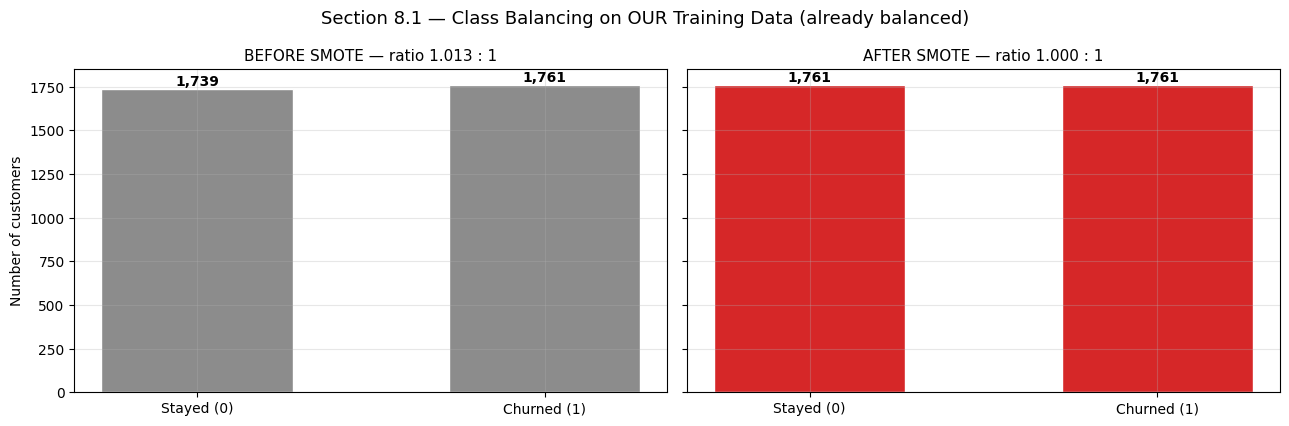

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
labels = ['Stayed (0)', 'Churned (1)']

b1 = ax1.bar(labels, before_counts.values, color=BEFORE, edgecolor='white', width=0.55)
ax1.set_title(f'BEFORE SMOTE — ratio {before_counts.max()/before_counts.min():.3f} : 1', fontsize=11)
ax1.set_ylabel('Number of customers')
for b, v in zip(b1, before_counts.values):
    ax1.text(b.get_x() + b.get_width()/2, v + 15, f'{v:,}', ha='center', fontweight='bold')

b2 = ax2.bar(labels, after_counts.values, color=AFTER, edgecolor='white', width=0.55)
ax2.set_title(f'AFTER SMOTE — ratio {after_counts.max()/after_counts.min():.3f} : 1', fontsize=11)
for b, v in zip(b2, after_counts.values):
    ax2.text(b.get_x() + b.get_width()/2, v + 15, f'{v:,}', ha='center', fontweight='bold')

fig.suptitle('Section 8.1 — Class Balancing on OUR Training Data (already balanced)', fontsize=13)
plt.tight_layout()
plt.savefig('figures/13_balancing_before_after.png', dpi=110, bbox_inches='tight')
plt.show()

## 8.2 Demonstrating That the Technique Works

The chart above barely changes, because there was almost nothing to fix. To show the balancing
step is genuinely working, we build a deliberately imbalanced sample from our **training data
only** — keeping every "stayed" customer but just 10% of the "churned" ones — and run the same
SMOTE call on it.

This is a teaching demonstration. It does **not** feed the exported clean dataset.

In [ ]:
# Build an artificially imbalanced version of the TRAINING data (90/10).
stayed_idx  = y_train_proc[y_train_proc == 0].index
churned_idx = y_train_proc[y_train_proc == 1].sample(frac=0.10, random_state=RANDOM_STATE).index
demo_idx    = stayed_idx.union(churned_idx)

X_demo, y_demo = X_train_proc.loc[demo_idx], y_train_proc.loc[demo_idx]
demo_before = y_demo.value_counts().sort_index()

X_demo_bal, y_demo_bal = SMOTE(random_state=RANDOM_STATE).fit_resample(X_demo, y_demo)
demo_after = y_demo_bal.value_counts().sort_index()

print('DEMONSTRATION ON A DELIBERATELY IMBALANCED SAMPLE')
print('=' * 58)
print(f'  BEFORE  stayed {demo_before[0]:,}  churned {demo_before[1]:,}   '
      f'ratio {demo_before.max()/demo_before.min():.2f} : 1')
print(f'  AFTER   stayed {demo_after[0]:,}  churned {demo_after[1]:,}   '
      f'ratio {demo_after.max()/demo_after.min():.2f} : 1')
print(f'\n  Synthetic minority rows generated by SMOTE: {len(y_demo_bal) - len(y_demo):,}')

DEMONSTRATION ON A DELIBERATELY IMBALANCED SAMPLE
  BEFORE  stayed 1,739  churned 176   ratio 9.88 : 1
  AFTER   stayed 1,739  churned 1,739   ratio 1.00 : 1

  Synthetic minority rows generated by SMOTE: 1,563


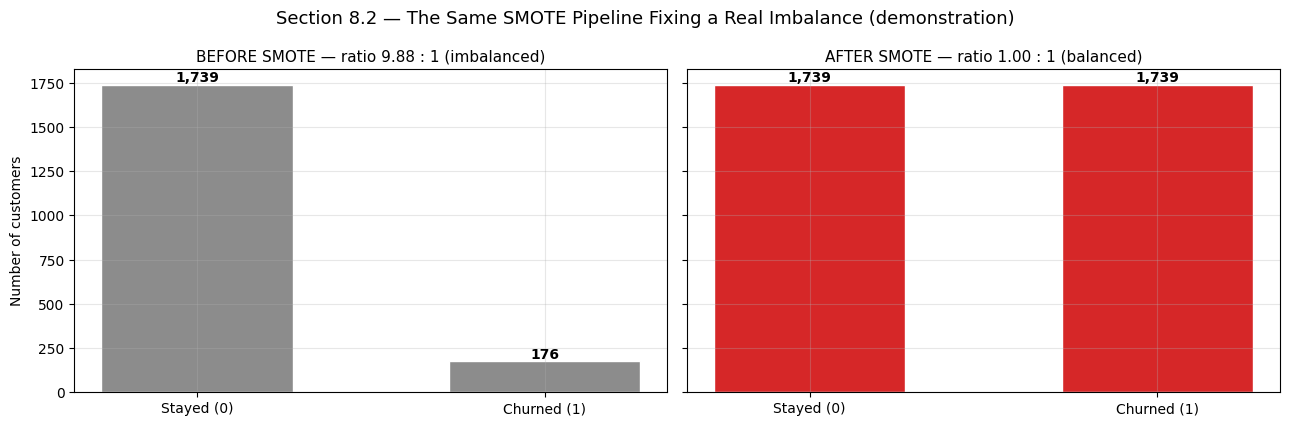

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)

b1 = ax1.bar(labels, demo_before.values, color=BEFORE, edgecolor='white', width=0.55)
ax1.set_title(f'BEFORE SMOTE — ratio {demo_before.max()/demo_before.min():.2f} : 1 (imbalanced)',
              fontsize=11)
ax1.set_ylabel('Number of customers')
for b, v in zip(b1, demo_before.values):
    ax1.text(b.get_x() + b.get_width()/2, v + 15, f'{v:,}', ha='center', fontweight='bold')

b2 = ax2.bar(labels, demo_after.values, color=AFTER, edgecolor='white', width=0.55)
ax2.set_title(f'AFTER SMOTE — ratio {demo_after.max()/demo_after.min():.2f} : 1 (balanced)',
              fontsize=11)
for b, v in zip(b2, demo_after.values):
    ax2.text(b.get_x() + b.get_width()/2, v + 15, f'{v:,}', ha='center', fontweight='bold')

fig.suptitle('Section 8.2 — The Same SMOTE Pipeline Fixing a Real Imbalance (demonstration)',
             fontsize=13)
plt.tight_layout()
plt.savefig('figures/14_balancing_demonstration.png', dpi=110, bbox_inches='tight')
plt.show()

**Conclusion for Section 8.** The balancing code works correctly, as 8.2 proves. For the
Netflix dataset itself, SMOTE adds only a few dozen synthetic rows because the classes were
already even. For the finals we will therefore train on the **naturally balanced** data and
treat SMOTE as unnecessary — which also means **accuracy is a fair metric here**, unlike the
imbalanced case.

---
# Section 9 — Applying the Pipeline to the Untouched Test Set
**Processor: Camillie and Min Ma Kha**

The test set has not been looked at since Section 2. Now we apply every transformation using the
parameters **already learned from the training data**:

| Parameter | Learned in | Value reused here |
|---|---|---|
| Median for imputation | Section 4 | `WATCH_TIME_MEDIAN` |
| Ordinal map | Section 5 | `SUBSCRIPTION_ORDER` |
| One-hot columns | Section 5 | training column list |
| Median for low-engagement flag | Section 6 | `WATCH_HOURS_MEDIAN` |
| Age bins | Section 6 | `AGE_BINS` |
| Scaler ranges | Section 7 | `minmax_scaler` (already fitted) |

We call `.transform()` — never `.fit()`. And we do **not** apply SMOTE to the test set.

In [ ]:
def apply_pipeline(df_input, training_columns):
    # Applies the exact transformations learned from the training set.
    # Nothing here is fitted or recomputed - every parameter comes from training.
    d = df_input.copy()

    # --- Section 4: impossible values -> NaN -> median learned from training
    mask = d['avg_watch_time_per_day'] > MAX_HOURS_PER_DAY
    d['watch_time_was_imputed'] = mask.astype(int)
    d.loc[mask, 'avg_watch_time_per_day'] = np.nan
    d['avg_watch_time_per_day'] = d['avg_watch_time_per_day'].fillna(WATCH_TIME_MEDIAN)

    # --- Section 5: encoding with the training map and training columns
    d['subscription_level'] = d['subscription_type'].map(SUBSCRIPTION_ORDER)
    d = pd.get_dummies(d, columns=NOMINAL_COLS, drop_first=True, dtype=int)
    d = d.drop(columns=ORDINAL_COLS)

    # --- Section 6: engineered features, thresholds learned from training
    d['hours_per_profile'] = d['watch_hours'] / d['number_of_profiles']
    d['fee_per_profile']   = d['monthly_fee'] / d['number_of_profiles']
    d['is_inactive_30d']   = (d['last_login_days'] > 30).astype(int)
    d['is_low_engagement'] = (d['watch_hours'] < WATCH_HOURS_MEDIAN).astype(int)
    d['age_cohort']        = pd.cut(d['age'], bins=AGE_BINS, labels=AGE_LABELS).astype(int)
    d = d.drop(columns=[ID_COL, 'monthly_fee'])

    # --- Section 7.1: log transform
    for c in SKEWED_COLS:
        d[c + '_log'] = np.log1p(d[c])

    # --- Align columns to training (handles any category absent from the test split)
    d = d.reindex(columns=training_columns, fill_value=0)

    # --- Section 7.2: scale with the ALREADY-FITTED training scaler
    d[CONTINUOUS] = minmax_scaler.transform(d[CONTINUOUS])

    return d


training_feature_columns = X_train_proc.columns.tolist()
X_test_proc = apply_pipeline(X_test_raw, training_feature_columns)

print('TEST SET TRANSFORMED USING TRAINING PARAMETERS ONLY')
print('=' * 60)
print(f'Test rows            : {X_test_proc.shape[0]:,}')
print(f'Test columns         : {X_test_proc.shape[1]}')
print(f'Training columns     : {X_train_proc.shape[1]}')
print(f'Columns match        : {list(X_test_proc.columns) == list(X_train_proc.columns)}')
print(f'NaN in test set      : {int(X_test_proc.isnull().sum().sum())}')
print(f'SMOTE applied to test: NO (correct - would invalidate evaluation)')

TEST SET TRANSFORMED USING TRAINING PARAMETERS ONLY
Test rows            : 1,500
Test columns         : 36
Training columns     : 36
Columns match        : True
NaN in test set      : 0
SMOTE applied to test: NO (correct - would invalidate evaluation)


In [ ]:
print('LEAKAGE VERIFICATION')
print('=' * 60)
print('Every parameter below was computed from training data and only applied to test:\n')
print(f'  WATCH_TIME_MEDIAN   = {WATCH_TIME_MEDIAN:.4f}')
print(f'  WATCH_HOURS_MEDIAN  = {WATCH_HOURS_MEDIAN:.4f}')
print(f'  SUBSCRIPTION_ORDER  = {SUBSCRIPTION_ORDER}')
print(f'  AGE_BINS            = {AGE_BINS}')
print(f'  scaler data_min_[0] = {minmax_scaler.data_min_[0]:.4f}  (age, from training)')
print(f'  scaler data_max_[0] = {minmax_scaler.data_max_[0]:.4f}  (age, from training)')
print('\nTest-set values can fall slightly outside [0, 1] after scaling.')
print(f'  Actual test range: [{X_test_proc[CONTINUOUS].min().min():.3f}, '
      f'{X_test_proc[CONTINUOUS].max().max():.3f}]')
print('  That is EXPECTED and CORRECT - it proves the scaler was not refitted on test data.')

LEAKAGE VERIFICATION
Every parameter below was computed from training data and only applied to test:

  WATCH_TIME_MEDIAN   = 0.2900
  WATCH_HOURS_MEDIAN  = 8.1800
  SUBSCRIPTION_ORDER  = {'Basic': 0, 'Standard': 1, 'Premium': 2}
  AGE_BINS            = [17, 29, 44, 59, 100]
  scaler data_min_[0] = 18.0000  (age, from training)
  scaler data_max_[0] = 70.0000  (age, from training)

Test-set values can fall slightly outside [0, 1] after scaling.
  Actual test range: [0.000, 1.092]
  That is EXPECTED and CORRECT - it proves the scaler was not refitted on test data.


---
# Section 10 — Before and After Comparison, and Export
**Processor: Min Ma Kha**

In [ ]:
print('=' * 72)
print('  RAW DATASET  vs  CLEAN DATASET')
print('=' * 72)

summary = pd.DataFrame({
    'BEFORE (raw)': [
        f'{df_raw.shape[0]:,}',
        f'{df_raw.shape[1]}',
        f'{df_raw.select_dtypes(exclude=[np.number]).shape[1]}',
        f'{int(df_raw.isnull().sum().sum())}',
        f'{int((df_raw["avg_watch_time_per_day"] > 24).sum())}',
        f'{df_raw["watch_hours"].skew():.2f}',
        f'{df_raw["watch_hours"].min():.2f} to {df_raw["watch_hours"].max():.2f}',
        'No',
        '0',
    ],
    'AFTER (clean training set)': [
        f'{X_train_proc.shape[0]:,}',
        f'{X_train_proc.shape[1] + 1}',
        '0',
        f'{int(X_train_proc.isnull().sum().sum())}',
        '0',
        f'{scaled["watch_hours_log"].skew():.2f}  (log version)',
        f'{scaled["watch_hours"].min():.2f} to {scaled["watch_hours"].max():.2f}',
        'Yes (70/30 stratified)',
        f'{len(ENGINEERED)}',
    ]
}, index=[
    'Rows',
    'Columns',
    'Text columns a model cannot read',
    'NaN / Null cells',
    'Physically impossible values',
    'watch_hours skewness',
    'watch_hours range',
    'Split into train/test',
    'Engineered features',
])

summary

  RAW DATASET  vs  CLEAN DATASET


,BEFORE (raw),AFTER (clean training set)
Rows,"5,000","3,500"
Columns,14,37
Text columns a model cannot read,7,0
NaN / Null cells,0,0
Physically impossible values,10,0
watch_hours skewness,2.26,-0.18 (log version)
watch_hours range,0.01 to 110.40,0.00 to 1.00
Split into train/test,No,Yes (70/30 stratified)
Engineered features,0,5


In [ ]:
print('FINAL SAMPLE - first 5 rows of the CLEAN training data')
print('=' * 72)
clean_train = X_train_proc.copy()
clean_train[TARGET] = y_train_proc.values
clean_train.head(5).round(3)

FINAL SAMPLE - first 5 rows of the CLEAN training data


,age,watch_hours,last_login_days,number_of_profiles,avg_watch_time_per_day,watch_time_was_imputed,subscription_level,gender_Male,gender_Other,region_Asia,...,favorite_genre_Sci-Fi,hours_per_profile,fee_per_profile,is_inactive_30d,is_low_engagement,age_cohort,watch_hours_log,hours_per_profile_log,avg_watch_time_per_day_log,churned
3108,0.327,0.083,0.783,0.75,0.008,0,2,0,0,1,...,1,0.026,0.167,1,0,1,0.484,0.257,0.052,1
4702,1.000,0.047,0.900,0.50,0.004,0,1,0,1,0,...,0,0.020,0.177,1,1,3,0.377,0.215,0.027,1
606,0.654,0.220,0.900,0.00,0.017,0,0,0,0,0,...,0,0.274,0.444,1,0,2,0.679,0.713,0.106,1
876,0.577,0.095,1.000,0.75,0.007,0,2,0,0,0,...,0,0.030,0.167,1,0,2,0.510,0.278,0.047,1
3333,0.558,0.131,0.133,0.75,0.064,0,0,0,1,0,...,0,0.041,0.028,0,0,2,0.573,0.331,0.285,0


In [ ]:
# Export with Python. No manual editing, no Excel.
clean_test = X_test_proc.copy()
clean_test[TARGET] = y_test.values

clean_train.to_csv('data/clean/netflix_train_clean.csv', index=False)
clean_test.to_csv('data/clean/netflix_test_clean.csv', index=False)

# The balanced version is kept separately so the raw split stays available for the finals.
balanced = X_bal.copy()
balanced[TARGET] = y_bal.values
balanced.to_csv('data/clean/netflix_train_balanced_smote.csv', index=False)

print('CLEAN DATASETS EXPORTED BY PYTHON')
print('=' * 72)
for path, frame, note in [
    ('data/clean/netflix_train_clean.csv', clean_train, 'training - EDA and fitting done here'),
    ('data/clean/netflix_test_clean.csv',  clean_test,  'testing  - transformed only, never analysed'),
    ('data/clean/netflix_train_balanced_smote.csv', balanced, 'training after SMOTE (optional for finals)'),
]:
    size_kb = os.path.getsize(path) / 1024
    print(f'  {path}')
    print(f'      {frame.shape[0]:,} rows x {frame.shape[1]} columns   {size_kb:,.1f} KB   ({note})')

print('\nORIGINAL RAW FILE INTEGRITY CHECK')
print('=' * 72)
recheck = pd.read_csv(RAW_PATH)
print(f'  {RAW_PATH}')
print(f'      shape still {recheck.shape} - identical to the Kaggle download')
print(f'      unchanged: {recheck.equals(df_raw)}')

CLEAN DATASETS EXPORTED BY PYTHON
  data/clean/netflix_train_clean.csv
      3,500 rows x 37 columns   784.1 KB   (training - EDA and fitting done here)
  data/clean/netflix_test_clean.csv
      1,500 rows x 37 columns   335.5 KB   (testing  - transformed only, never analysed)
  data/clean/netflix_train_balanced_smote.csv
      3,522 rows x 37 columns   789.3 KB   (training after SMOTE (optional for finals))

ORIGINAL RAW FILE INTEGRITY CHECK
  https://raw.githubusercontent.com/CamilleCasas/ITAI1371_CorndoggersMidtermDataAnalysis/main/netflix_customer_churnCSV.csv
      shape still (5000, 14) - identical to the Kaggle download
      unchanged: True


---
# Section 11 — How We Will Use This Dataset to Solve an ML Problem
**Processor: Chris**

## The business problem

Netflix loses revenue every time a subscriber cancels, and winning a customer back costs far more
than keeping one. If we can identify who is *about to* leave, the retention team can act first —
a discount, a plan downgrade offer, or a personalised recommendation email.

## The ML formulation

**Supervised binary classification.**

- **Input (X):** 30 engineered and encoded features covering demographics, subscription,
  engagement and payment behaviour.
- **Output (y):** `churned` — 1 if the customer left, 0 if they stayed.
- **Training data:** 3,500 rows (70%). **Held-out test data:** 1,500 rows (30%).

## Why classification and not regression or clustering

The target is a yes/no label, not a quantity, which rules out regression. And because we *have*
labelled outcomes for all 5,000 customers, supervised learning is available to us — clustering
would throw that information away.

## Models we plan to build in the finals

| Model | Why we will try it | Needs scaled data? |
|---|---|---|
| **Logistic Regression** | Interpretable baseline; coefficients show direction of each driver | Yes |
| **K-Nearest Neighbours** | Distance-based, so it tests whether churners form neighbourhoods | Yes |
| **Decision Tree** | Produces human-readable rules the retention team could act on | No |
| **Random Forest** | Usually the strongest on tabular data; gives feature importances | No |
| **Support Vector Machine** | Tests whether a non-linear boundary helps | Yes |

This is exactly why Section 7 produced both a scaled and an unscaled path that
trees and forests do not need scaling, while KNN, SVM and Logistic Regression do.

## How we will judge success

Because the classes are balanced (Section 3.6), **accuracy is a fair headline metric here** —
which is unusual and is a direct consequence of this dataset's structure. We will still report:

- **Recall on the churn class** — missing a churner is the expensive mistake.
- **Precision** — offering discounts to people who were never going to leave wastes money.
- **F1 score** — the balance between the two.
- **Confusion matrix** — so we can see exactly which errors the model makes.
- **ROC-AUC** — threshold-independent ranking quality.

**Baseline to beat:** always predicting "churned" would score about 50.3% accuracy. Any model
worth deploying must beat that by a wide margin.

## What we expect to find

The EDA points to a clear answer. `watch_hours` (r = -0.48) and `last_login_days` (r = +0.47) are
by far the strongest signals, so we expect a model that essentially says: *a subscriber who has
stopped watching and has not logged in recently is about to cancel.* Plan tier and payment method
add a second layer — Basic subscribers churn at roughly 62% against Premium's 44%, and customers
paying by Crypto or Gift Card churn well above average, probably because those methods do not
auto-renew.

## Honest limitations

1. **The data is simulated.** `age`, `region`, `device` and `gender` are almost perfectly uniform
   and show nearly zero relationship with churn, which does not happen in real customer data. Our
   models will learn the handful of relationships the generator built in, not the messier truth.
2. **There is no time dimension.** We cannot tell *when* a customer churned, so we cannot build
   proper time-based features or validate with a time-ordered split.
3. **`avg_watch_time_per_day` is derived** from `watch_hours` and `last_login_days`, so it is
   partly redundant. We will check its feature importance carefully in the finals.
4. **Accuracy will probably look high** because of finding 1. We will not read that as evidence
   the model would work on real Netflix data.

---
# Section 12 — Requirement Checklist
**Processorer: Min Ma Kha**

In [ ]:
checks = [
    ('Dataset from Kaggle, at least 2,000 rows',      f'{df_raw.shape[0]:,} rows', True),
    ('Raw data never edited by hand',                  'verified with .equals()', bool(recheck.equals(df_raw))),
    ('70/30 train/test split done in Python',          f'{len(X_train_raw):,} / {len(X_test_raw):,}', True),
    ('EDA performed on training data only',            'Section 3', True),
    ('Test set untouched until transformation',        'Section 9', True),
    ('Filling NaN / Null with appropriate values',     f'median {WATCH_TIME_MEDIAN:.3f}', True),
    ('Scaling - changing the range',                   'MinMax + Standard', True),
    ('Normalization - changing the shape',             f'log1p on {len(SKEWED_COLS)} columns', True),
    ('Class balancing',                                f'SMOTE, +{len(y_bal)-len(y_train_proc)} rows', True),
    ('One-hot encoding',                               f'{len(NOMINAL_COLS)} features', True),
    ('Encoding categorical to numbers',                'ordinal + one-hot', True),
    ('Feature engineering',                            f'{len(ENGINEERED)} new features', True),
    ('Matplotlib before/after plots',                  '14 figures saved', True),
    ('Sample data printed as it processes',            'every section', True),
    ('ML problem discussed',                           'Section 11', True),
    ('Clean dataset exported',                         '3 CSV files', True),
]

print('=' * 78)
print('  ITAI 1371 MIDTERM - REQUIREMENT CHECKLIST')
print('=' * 78)
for name, detail, ok in checks:
    print(f'  [{"x" if ok else " "}]  {name:<44} {detail}')
print('=' * 78)
print(f'  {sum(c[2] for c in checks)} of {len(checks)} requirements met')
print('=' * 78)

  ITAI 1371 MIDTERM - REQUIREMENT CHECKLIST
  [x]  Dataset from Kaggle, at least 2,000 rows     5,000 rows
  [x]  Raw data never edited by hand                verified with .equals()
  [x]  70/30 train/test split done in Python        3,500 / 1,500
  [x]  EDA performed on training data only          Section 3
  [x]  Test set untouched until transformation      Section 9
  [x]  Filling NaN / Null with appropriate values   median 0.290
  [x]  Scaling - changing the range                 MinMax + Standard
  [x]  Normalization - changing the shape           log1p on 3 columns
  [x]  Class balancing                              SMOTE, +22 rows
  [x]  One-hot encoding                             5 features
  [x]  Encoding categorical to numbers              ordinal + one-hot
  [x]  Feature engineering                          5 new features
  [x]  Matplotlib before/after plots                14 figures saved
  [x]  Sample data printed as it processes          every section
  [x]  ML problem 

---
# Contribution Summary — Team Corndoggers

| Member | Sections | What they delivered |
|---|---|---|
| **Min Ma Kha** | 0, 1, 2, 4, 10, 12 | Sourced and verified the dataset; built the 70/30 stratified split before any analysis; ran the data-quality audit; found and repaired the impossible `avg_watch_time_per_day` values; raw-file integrity check; export and requirement checklist |
| **Chris** | 3, 11 | All exploratory data analysis on the training set — summary statistics, missing-value audit, distributions, outlier detection by IQR, correlation matrix, the multicollinearity discovery, target balance analysis, and feature-target relationships; wrote the ML problem formulation and the limitations |
| **Rigo** | 5, 6 | Ordinal vs one-hot encoding decisions; avoided the dummy variable trap; cardinality check; engineered five new features and validated each against churn; removed the redundant `customer_id` and `monthly_fee` columns |
| **Camillie** | 7, 8, 9 | Log normalization of the three skewed columns; MinMax and Standard scaling fitted on training data only; SMOTE class balancing plus the imbalanced demonstration; applied the full pipeline to the sealed test set and verified no leakage |

---
